# 属性条件付き予測と公平性：6 種類の図

CheXpert race-known、年齢2区分 × race4区分、seed 42/43/44。
ResNet-50 / Spatial LoRA (stage3–4 + fc) / Spatial LoRA (fc only) を比較する。
図1–4は **best validation AUROC checkpoint の test**、図6は **validation の学習推移**。
動作点の閾値は全群共通の0.5。陽性は No Finding。worst-FPR = 群別FPRの最大値。

「ERMの属性条件付けだけでは公平性が改善しない」を仮説として検証し、結論には固定しない。
エラーバー／帯は3 seedの標本SDであり、患者の標本誤差や有意差を表さない。

**比較上の制約**：EO rateはtrainの20%を双対更新に使い、残り80%をセル均等抽出する。
ERM/GroupDROとの比較には損失以外の違いが含まれる。2-stageの親はそのheld-outを学習済み。

再実行：`uv run jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=hypernet-fairness analysis/hypernet_conditioning_grid/requested_figures.ipynb`。
図はPNG/PDF、集計はCSVへ保存する。入力不足時には止め、欠けた条件を黙って省かない。

In [1]:
import base64
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
from IPython.display import display
from matplotlib.backends.backend_pdf import PdfPages

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, local_data_path, study_dir  # noqa: E402
from analysis.hypernet_conditioning_grid.compute import runs  # noqa: E402
from analysis.hypernet_conditioning_grid.grid_metrics import GROUP_LABELS, load_split  # noqa: E402
from analysis.hypernet_conditioning_grid.requested_analysis import (  # noqa: E402
    KEYS,
    best_cache_files,
    learning_tables,
    prediction_tables,
)

PACKAGE = study_dir("hypernet_conditioning_grid")
RESULTS = PACKAGE / "results" / "requested_figures"
FIGURES = PACKAGE / "figures" / "requested_figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.style.use(STYLE_SHEET)
BOOK = PdfPages(FIGURES / "all_requested_figures.pdf")
MODEL = {"resnet": "ResNet-50", "spatial_lora": "Spatial LoRA (S3–4 + fc)", "spatial_lora_fc": "Spatial LoRA (fc only)"}
STAGE = {"one_stage": "1-stage", "two_stage": "2-stage (frozen ResNet)"}
OBJECTIVE = {"erm": "ERM", "group_dro": "GroupDRO", "eo_rate": "EO rate"}
COLORS = {"erm": "#0173B2", "group_dro": "#DE8F05", "eo_rate": "#029E73"}
FAIRNESS = ["auroc_gap", "eopp0", "worst_group_auroc", "worst_fpr"]
GROUP_METRICS = ["auroc", "bacc", "tpr", "fpr"]
TITLES = {
    "auroc_gap": "AUC gap ↓",
    "eopp0": "Eopp0 (FPR gap) ↓",
    "worst_group_auroc": "Worst-AUC ↑",
    "worst_fpr": "Worst-FPR ↓",
    "auroc": "AUROC ↑",
    "bacc": "BACC ↑",
    "tpr": "TPR ↑",
    "fpr": "FPR ↓",
}
MODELS = list(MODEL)
OBJECTIVES = list(OBJECTIVE)
table = runs()
assert len(table) == 45 and table.groupby(KEYS).seed.apply(set).eq({42, 43, 44}).all()
display(table.groupby(KEYS).size().rename("seeds").to_frame())

seeds
procedure model           objective       
one_stage resnet          eo_rate        3
                          erm            3
                          group_dro      3
          spatial_lora    eo_rate        3
                          erm            3
                          group_dro      3
          spatial_lora_fc eo_rate        3
                          erm            3
                          group_dro      3
two_stage spatial_lora    eo_rate        3
                          erm            3
                          group_dro      3
          spatial_lora_fc eo_rate        3
                          erm            3
                          group_dro      3

## 入力と学習ログの検算

run.json のbest選択とval AUROC最大値、30 epochの連続性、qの総和を確認する。
TPR/FPRは accuracy = p·TPR + (1−p)·TNR、2·BACC = TPR + TNR を解いて復元する。
各best epochで予測cacheから直接計算した値との差を記録する。学習時はbf16-mixed、cacheはfloat32推論なので完全一致ではない。
復元されたTP/FPが整数件数に一致することも確認する。worst-FPRはこの式からは復元できない。

In [2]:
history, q_history, selections = learning_tables(table, PACKAGE)
history.to_csv(RESULTS / "validation_history_by_seed.csv", index=False)
q_history.to_csv(RESULTS / "q_history_by_seed.csv", index=False)
selections.to_csv(RESULTS / "best_epochs.csv", index=False)
files = {split: best_cache_files(table, PACKAGE, split) for split in ("test", "val")}
missing = [(split, r) for split in files for r in table.run_id if (r, "best") not in files[split]]
assert not missing, f"best cache が不足: {missing}"
test, groups, provenance = prediction_tables(
    table, PACKAGE, files["test"], "test", local_data_path("data/chexpert/splits_race_known/test.csv")
)
validation, val_groups, val_provenance = prediction_tables(
    table, PACKAGE, files["val"], "val", local_data_path("data/chexpert/splits_race_known/val.csv")
)
selected_history = history.merge(selections[["run_id", "best_epoch"]], on="run_id").query("epoch == best_epoch")
checks = selected_history.merge(validation, on="run_id", suffixes=("_log", "_cache"))
check_metrics = ["auroc", "bacc", "tpr", "fpr", "auroc_gap", "eopp0", "worst_group_auroc"]
errors = pd.DataFrame({"run_id": checks.run_id})
for metric in check_metrics:
    errors[metric] = checks[f"{metric}_log"] - checks[f"{metric}_cache"]
# 学習時はbf16-mixed、cacheはfloat32推論。異なる数値精度のため完全一致を要求しない。
# 復元そのものは混同行列の整数件数と照合し、cacheとの差は全run・全指標で保存する。
val_frame = load_split("val")
for metric, n in (("tpr", int(val_frame.target.sum())), ("fpr", int((val_frame.target == 0).sum()))):
    reconstructed_counts = history[metric].to_numpy() * n
    assert np.abs(reconstructed_counts - np.round(reconstructed_counts)).max() < 0.01
assert np.isfinite(errors[check_metrics].to_numpy()).all()
errors.to_csv(RESULTS / "validation_cache_log_errors.csv", index=False)
test.to_csv(RESULTS / "test_by_seed.csv", index=False)
groups.to_csv(RESULTS / "test_groups_by_seed.csv", index=False)
pd.concat([provenance, val_provenance]).to_csv(RESULTS / "provenance.csv", index=False)
counts = groups[["group", "group_label", "n_pos", "n_neg"]].drop_duplicates().sort_values("group")
assert len(counts) == 8
counts.to_csv(RESULTS / "test_group_counts.csv", index=False)
display(counts)
print("最大cache/log誤差:", np.abs(errors[check_metrics].to_numpy()).max())

,group,group_label,n_pos,n_neg
0,0,<65 × White,823,5339
1,1,<65 × Asian,186,980
2,2,<65 × Black,126,766
3,3,<65 × Others,402,2064
4,4,≥65 × White,365,5961
5,5,≥65 × Asian,52,1009
6,6,≥65 × Black,22,303
7,7,≥65 × Others,68,1151


最大cache/log誤差: 0.004775006403275467


## 集計と図の共通設定

gapやworstは各seed内で8群から求めてから平均する。群のseed平均を先に取ってからgapを計算しない。
各図の点はseed、太いマーカーとエラーバーは平均±SD。群別図の陽性数はTPR、陰性数はFPRの分母。
≥65 × Black はtest陽性22件なので、TPRやAUROCを大きな群と同じ精度で解釈しない。

In [3]:
def aggregate(frame, keys, metrics):
    grouped = frame.groupby(keys, sort=False)[metrics]
    return grouped.mean().join(grouped.std().add_suffix("_sd")).reset_index()


means = aggregate(test, KEYS, FAIRNESS + GROUP_METRICS)
group_means = aggregate(groups, KEYS + ["group", "group_label", "n_pos", "n_neg"], GROUP_METRICS)
means.to_csv(RESULTS / "test_mean_sd.csv", index=False)
group_means.to_csv(RESULTS / "test_groups_mean_sd.csv", index=False)
history_means = aggregate(history, KEYS + ["epoch"], [m for m in FAIRNESS + GROUP_METRICS if m != "worst_fpr"])
history_means.to_csv(RESULTS / "validation_history_mean_sd.csv", index=False)


def save_figure(fig, name):
    BOOK.savefig(fig)
    for extension in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{extension}")
    plt.show()
    plt.close(fig)


fair_limits = {}
for metric in FAIRNESS:
    lower = 0 if metric != "worst_group_auroc" else max(0, test[metric].min() - 0.02)
    upper = min(1, test[metric].max() + 0.03)
    fair_limits[metric] = (lower, upper)


def point_panel(ax, frame, metric, categories, category_column, labels):
    for x, category in enumerate(categories):
        values = frame.loc[frame[category_column] == category].sort_values("seed")[metric].to_numpy()
        assert len(values) == 3
        color = COLORS.get(category, f"C{x}")
        ax.scatter(x + np.linspace(-0.08, 0.08, 3), values, s=22, alpha=0.55, color=color)
        ax.errorbar(x, values.mean(), yerr=values.std(ddof=1), fmt="D", markersize=5, capsize=4, color=color)
    ax.set_xticks(range(len(categories)), [labels[c] for c in categories], fontsize=9)
    ax.set_title(TITLES[metric])
    ax.set_ylim(*fair_limits[metric])
    if metric in ("auroc_gap", "eopp0", "worst_fpr", "fpr"):
        ax.set_ylim(bottom=0)


def group_panels(frame, category_column, categories, labels, title, name):
    fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
    for ax, metric in zip(axes.flat, GROUP_METRICS, strict=True):
        for i, category in enumerate(categories):
            selected = frame.loc[frame[category_column] == category]
            stats = selected.groupby("group")[metric].agg(["mean", "std"]).reindex(range(8))
            assert len(selected) == 24 and stats.notna().all().all()
            x = np.arange(8) + (i - (len(categories) - 1) / 2) * 0.18
            ax.errorbar(
                x,
                stats["mean"],
                yerr=stats["std"],
                fmt="o",
                capsize=3,
                label=labels[category],
                color=COLORS.get(category, f"C{i}"),
                markersize=5,
            )
        ax.set_title(TITLES[metric])
        ax.set_ylim(0, 1)
        tick_labels = [f"{r.group_label}\n+{r.n_pos} / −{r.n_neg}" for r in counts.itertuples()]
        ax.set_xticks(range(8), tick_labels, rotation=25, ha="right")
    axes[0, 0].legend(loc="lower left", fontsize=9)
    fig.suptitle(
        title + "\nTest | best val AUROC checkpoint | mean ± SD, 3 seeds | + positives / − negatives", fontsize=13
    )
    save_figure(fig, name)

## 1. ERMの公平性：モデル横断比較

1-stageと2-stageを分ける。2-stageのResNetは継続学習したモデルではなく、凍結前の親ERMを参考線として再掲する。
AUC gap・Eopp0・worst-FPRは低いほど、worst-AUCは高いほどよい。

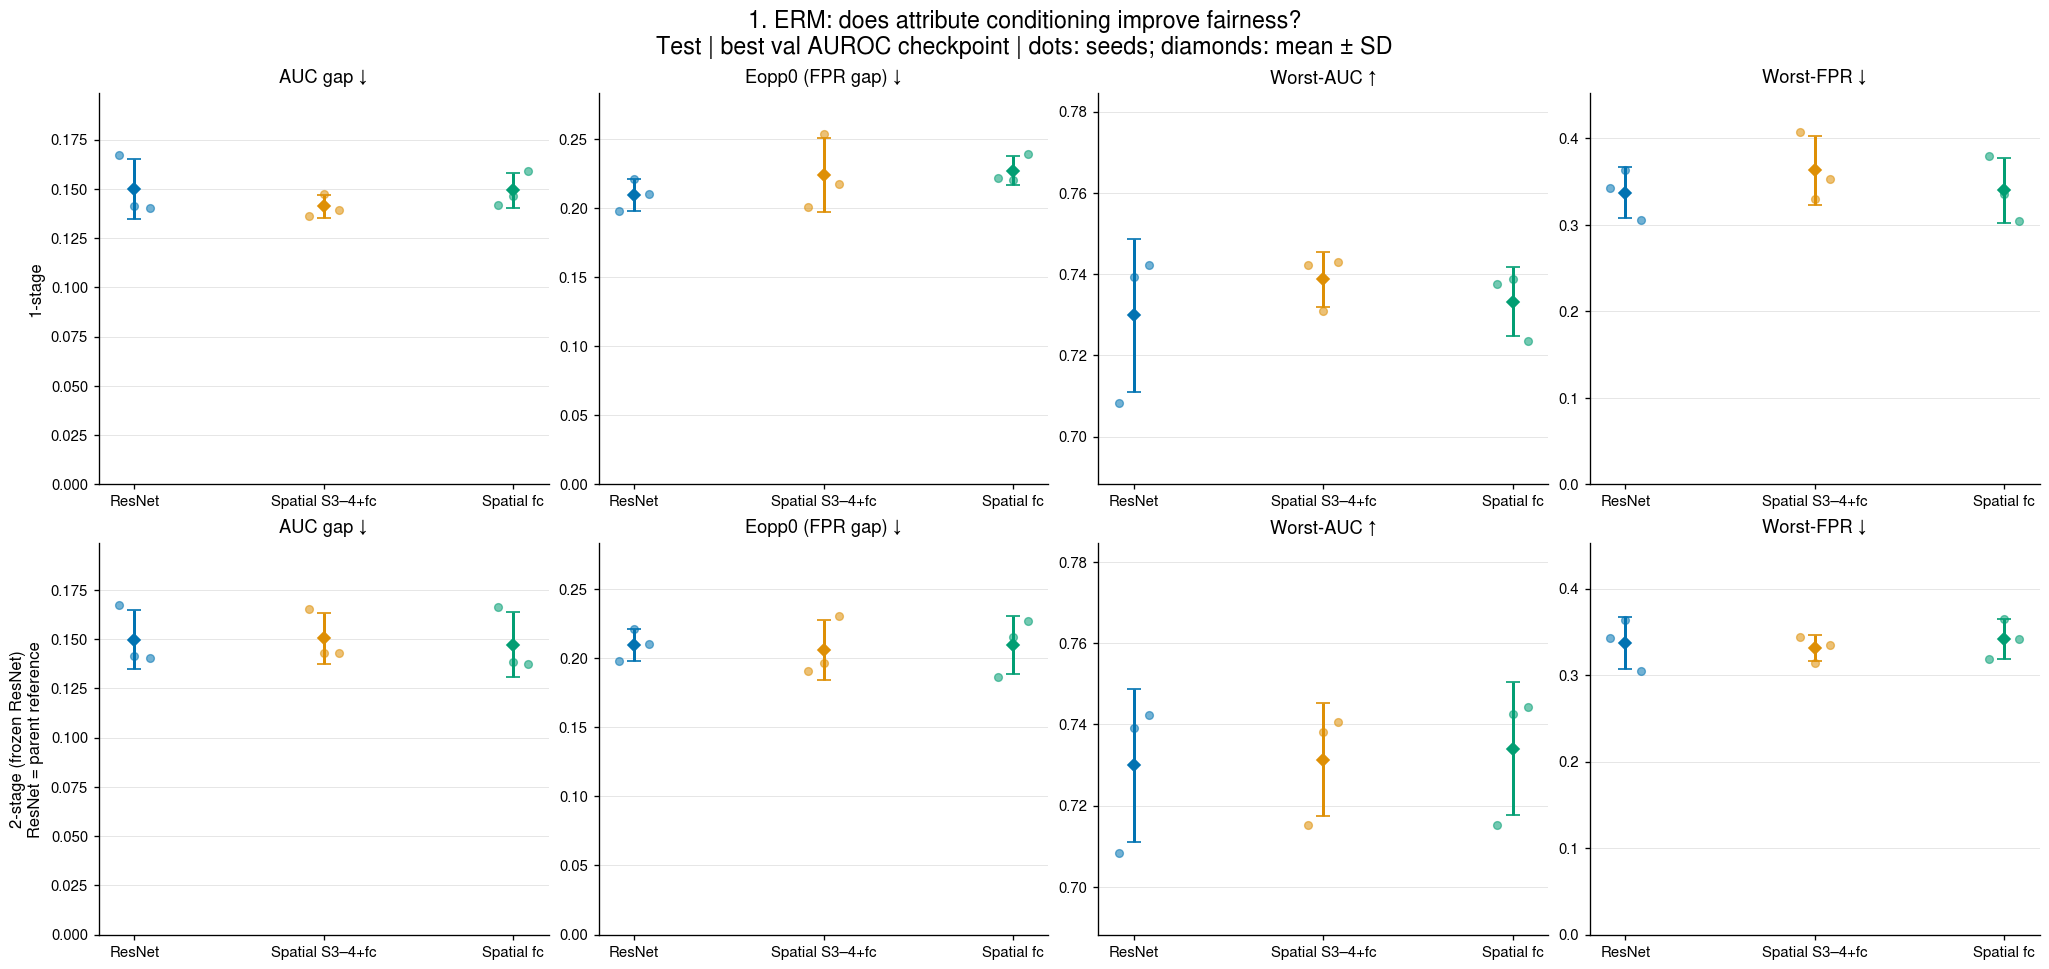

,procedure,model,objective,auroc_gap,eopp0,worst_group_auroc,worst_fpr
0,one_stage,resnet,erm,0.149732,0.209649,0.729907,0.337075
1,one_stage,spatial_lora,erm,0.141147,0.223677,0.738735,0.363265
10,two_stage,spatial_lora_fc,erm,0.147229,0.209545,0.733999,0.341894
11,one_stage,spatial_lora_fc,erm,0.149196,0.226864,0.733233,0.339796
14,two_stage,spatial_lora,erm,0.150390,0.205844,0.731329,0.330952


In [4]:
erm = test.query("objective == 'erm'")
erm_groups = groups.query("objective == 'erm'")
erm_labels = {"resnet": "ResNet", "spatial_lora": "Spatial S3–4+fc", "spatial_lora_fc": "Spatial fc"}
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for row, procedure in enumerate(STAGE):
    selected = erm.loc[erm.procedure == procedure]
    if procedure == "two_stage":
        selected = pd.concat([selected, erm.query("model == 'resnet'")])
    for ax, metric in zip(axes[row], FAIRNESS, strict=True):
        point_panel(ax, selected, metric, MODELS, "model", erm_labels)
    axes[row, 0].set_ylabel(STAGE[procedure] + ("\nResNet = parent reference" if row else ""))
fig.suptitle(
    "1. ERM: does attribute conditioning improve fairness?"
    "\nTest | best val AUROC checkpoint | dots: seeds; diamonds: mean ± SD",
    fontsize=14,
)
save_figure(fig, "01_erm_fairness")
display(means.query("objective == 'erm'")[KEYS + FAIRNESS])

観察：1-stageのS3–4＋fcはResNetより平均AUC gapが小さくworst-AUCが高いが、Eopp0とworst-FPRは高い。2-stageを含めても、4指標がそろって改善するとはいえない。

## 2. ERMの8群別性能

gapの縮小が最悪群の改善か、良い群の悪化かを切り分ける。群順と軸範囲は全図で固定する。

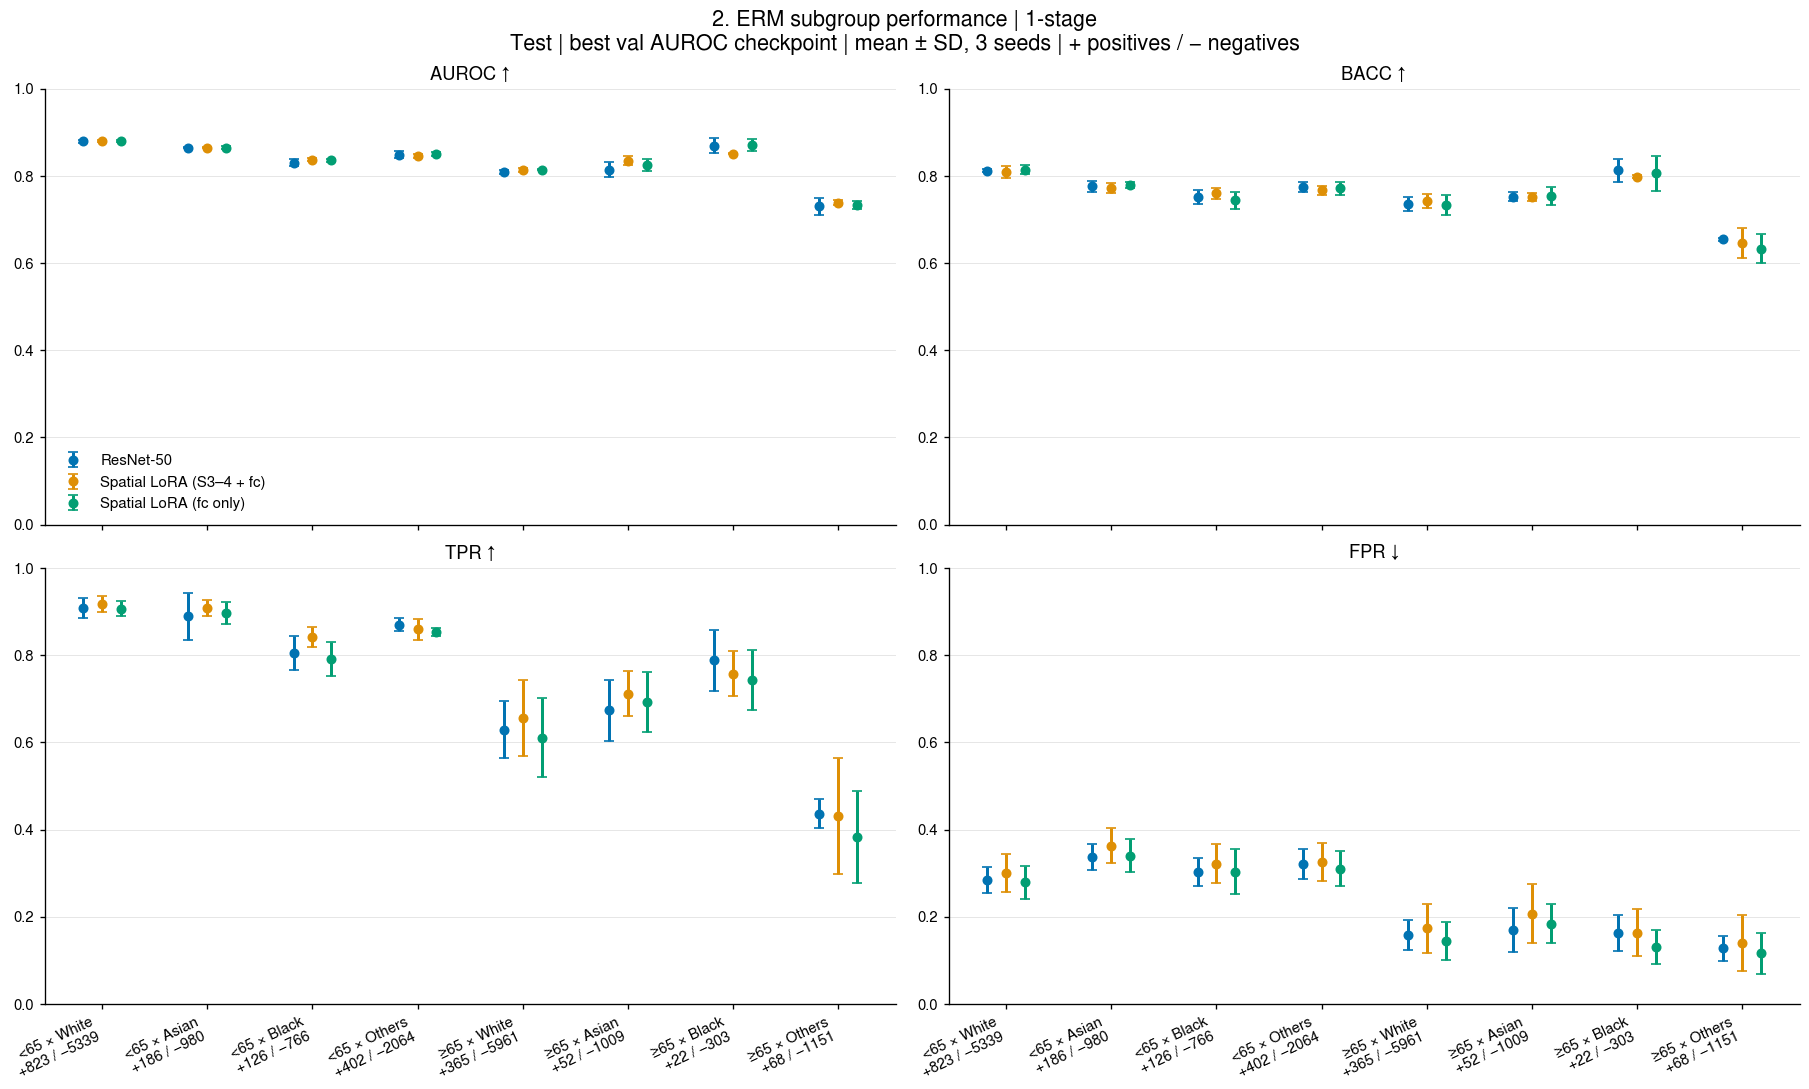

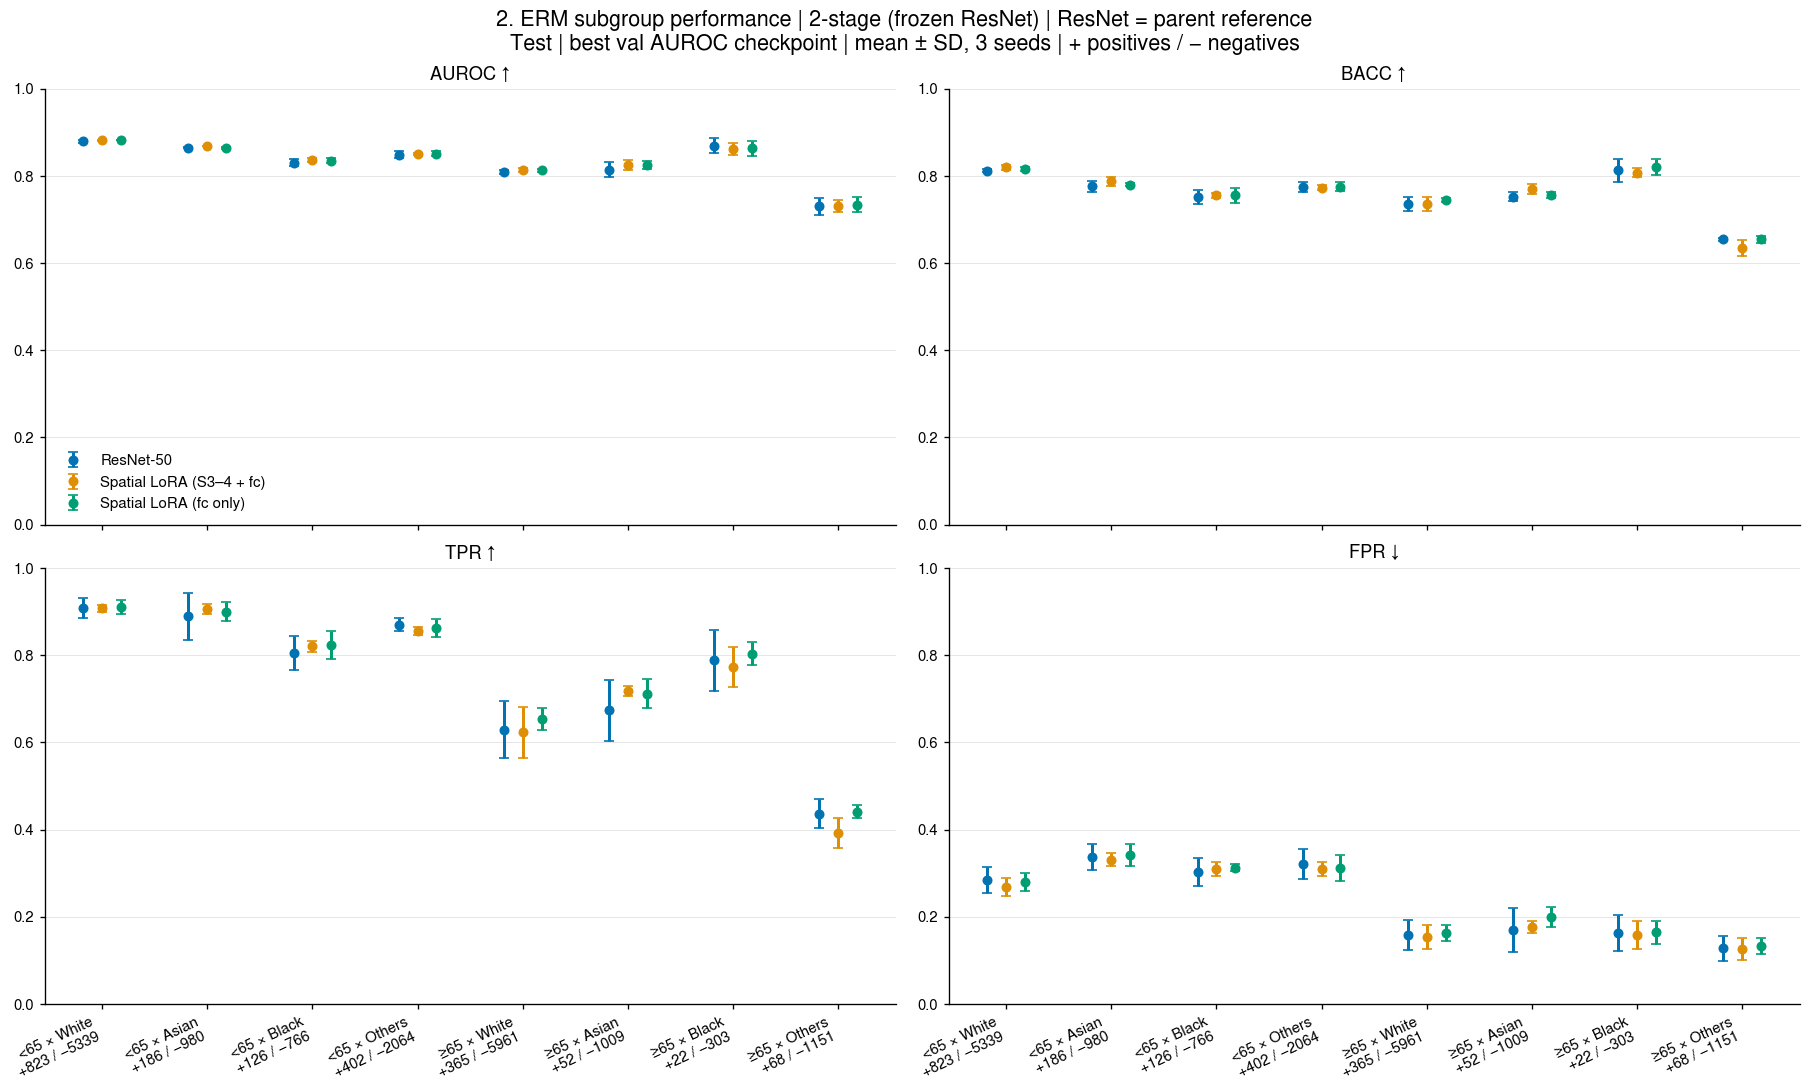

In [5]:
for procedure in STAGE:
    selected = erm_groups.loc[erm_groups.procedure == procedure]
    if procedure == "two_stage":
        selected = pd.concat([selected, erm_groups.query("model == 'resnet'")])
    extra = " | ResNet = parent reference" if procedure == "two_stage" else ""
    group_panels(
        selected,
        "model",
        MODELS,
        MODEL,
        "2. ERM subgroup performance | " + STAGE[procedure] + extra,
        f"02_erm_groups_{procedure}",
    )

観察：1-stageのS3–4＋fcでは、65歳以上×OthersのAUROCが上がる一方、TPR・BACCは下がる。群別AUROCの上昇だけでは固定閾値での性能改善とはいえない。

## 3. 公平性損失を加えた場合

同じSpatial LoRA構成・同じ学習手順のERMを対照に、GroupDROとEO rateを並べる。
1-stageと2-stageでそれぞれ3手法を比較するので、凍結の効果を損失の効果に混ぜない。

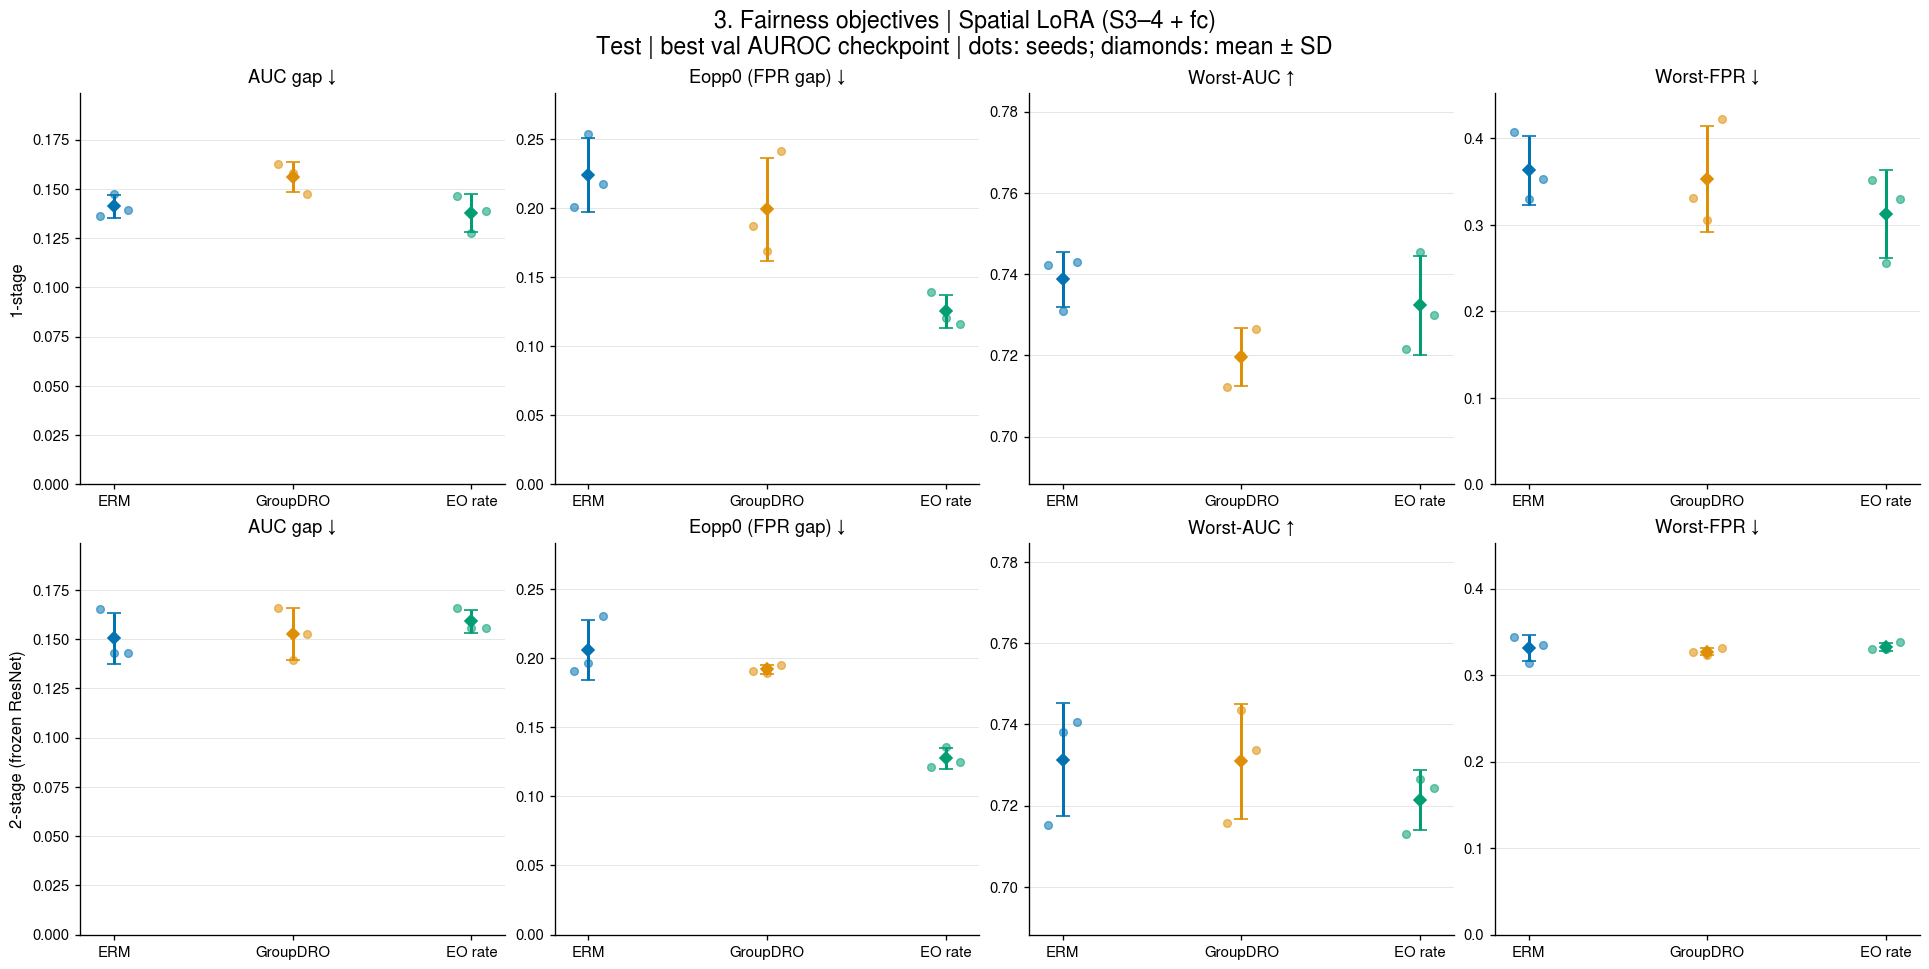

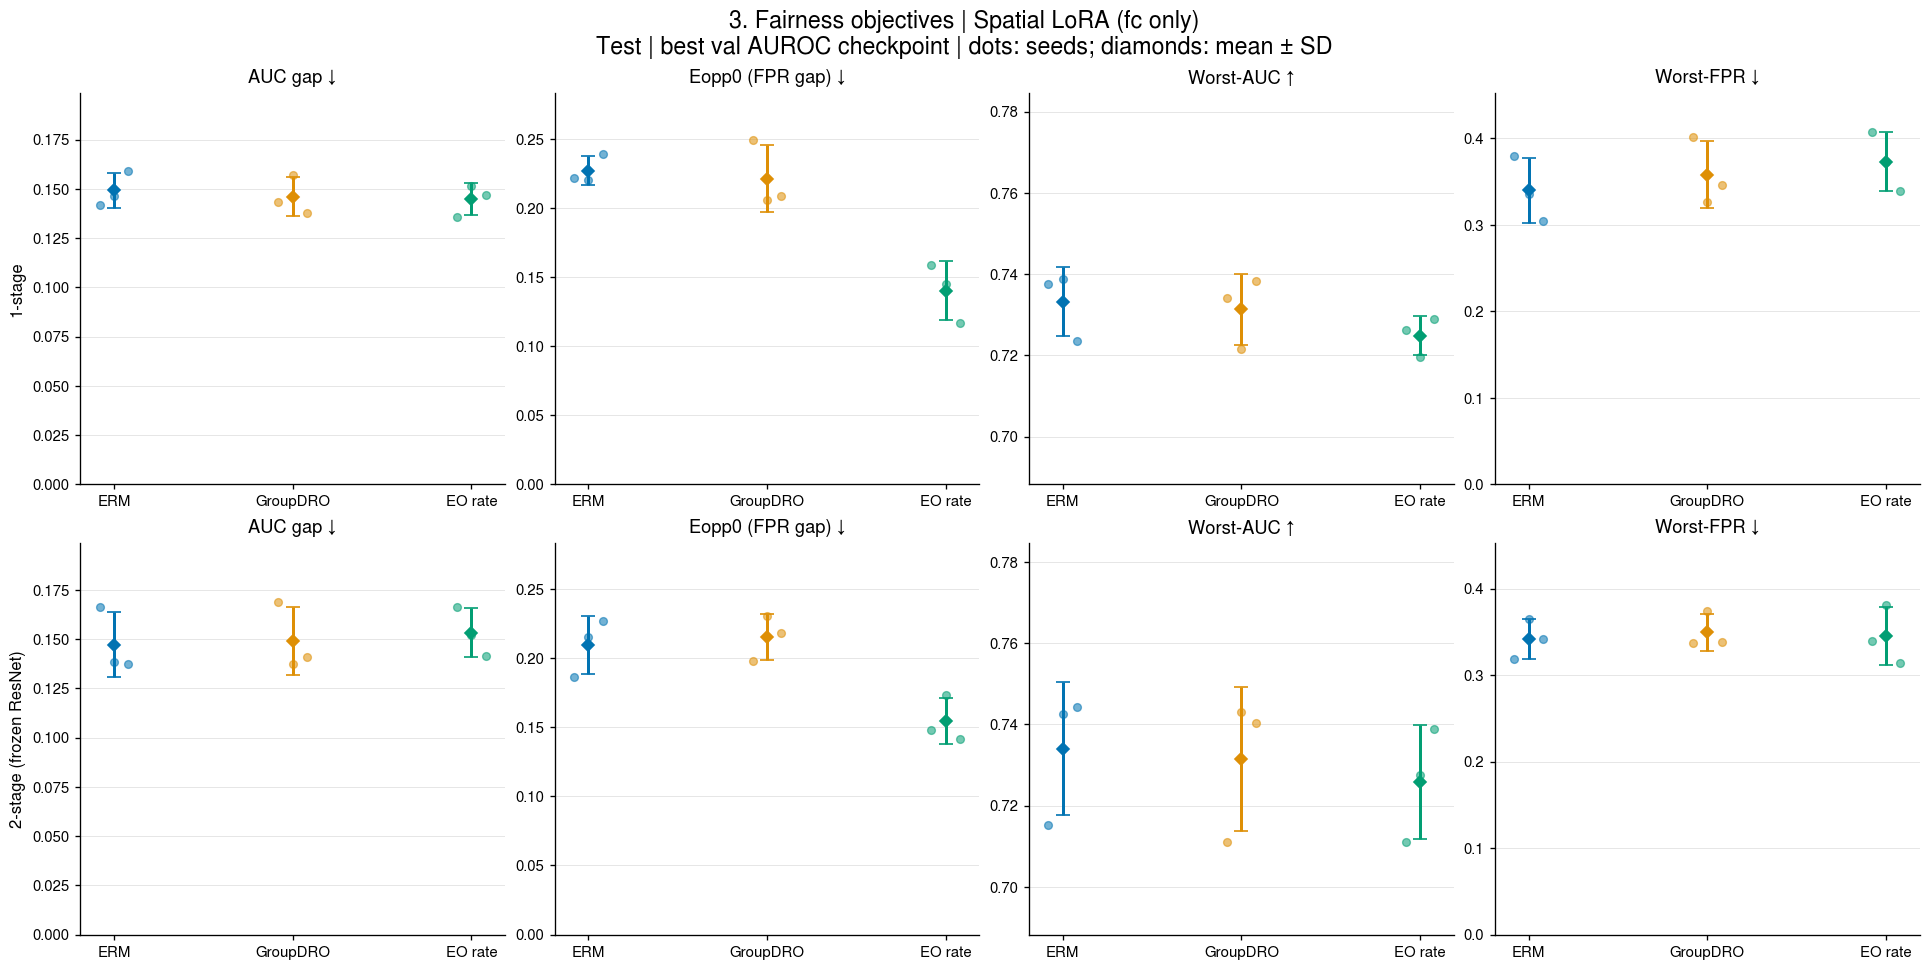

In [6]:
for model in ("spatial_lora", "spatial_lora_fc"):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for row, procedure in enumerate(STAGE):
        selected = test.loc[(test.model == model) & (test.procedure == procedure)]
        for ax, metric in zip(axes[row], FAIRNESS, strict=True):
            point_panel(ax, selected, metric, OBJECTIVES, "objective", OBJECTIVE)
        axes[row, 0].set_ylabel(STAGE[procedure])
    fig.suptitle(
        "3. Fairness objectives | "
        + MODEL[model]
        + "\nTest | best val AUROC checkpoint | dots: seeds; diamonds: mean ± SD",
        fontsize=14,
    )
    save_figure(fig, f"03_objective_fairness_{model}")

観察：S3–4＋fc・1-stageのEO-rateは、ERMよりEopp0（0.2237→0.1251）とworst-FPR（0.3633→0.3128）が下がる。ただし全体AUROCは0.8621→0.8461。2-stageのEO-rateではEopp0が下がる一方、worst-FPRはほぼ変わらない。

## 4. 公平性損失を加えた場合の8群別性能

FPRだけを下げ、同時にTPRも下げた場合は、その両方が分かるよう並べる。

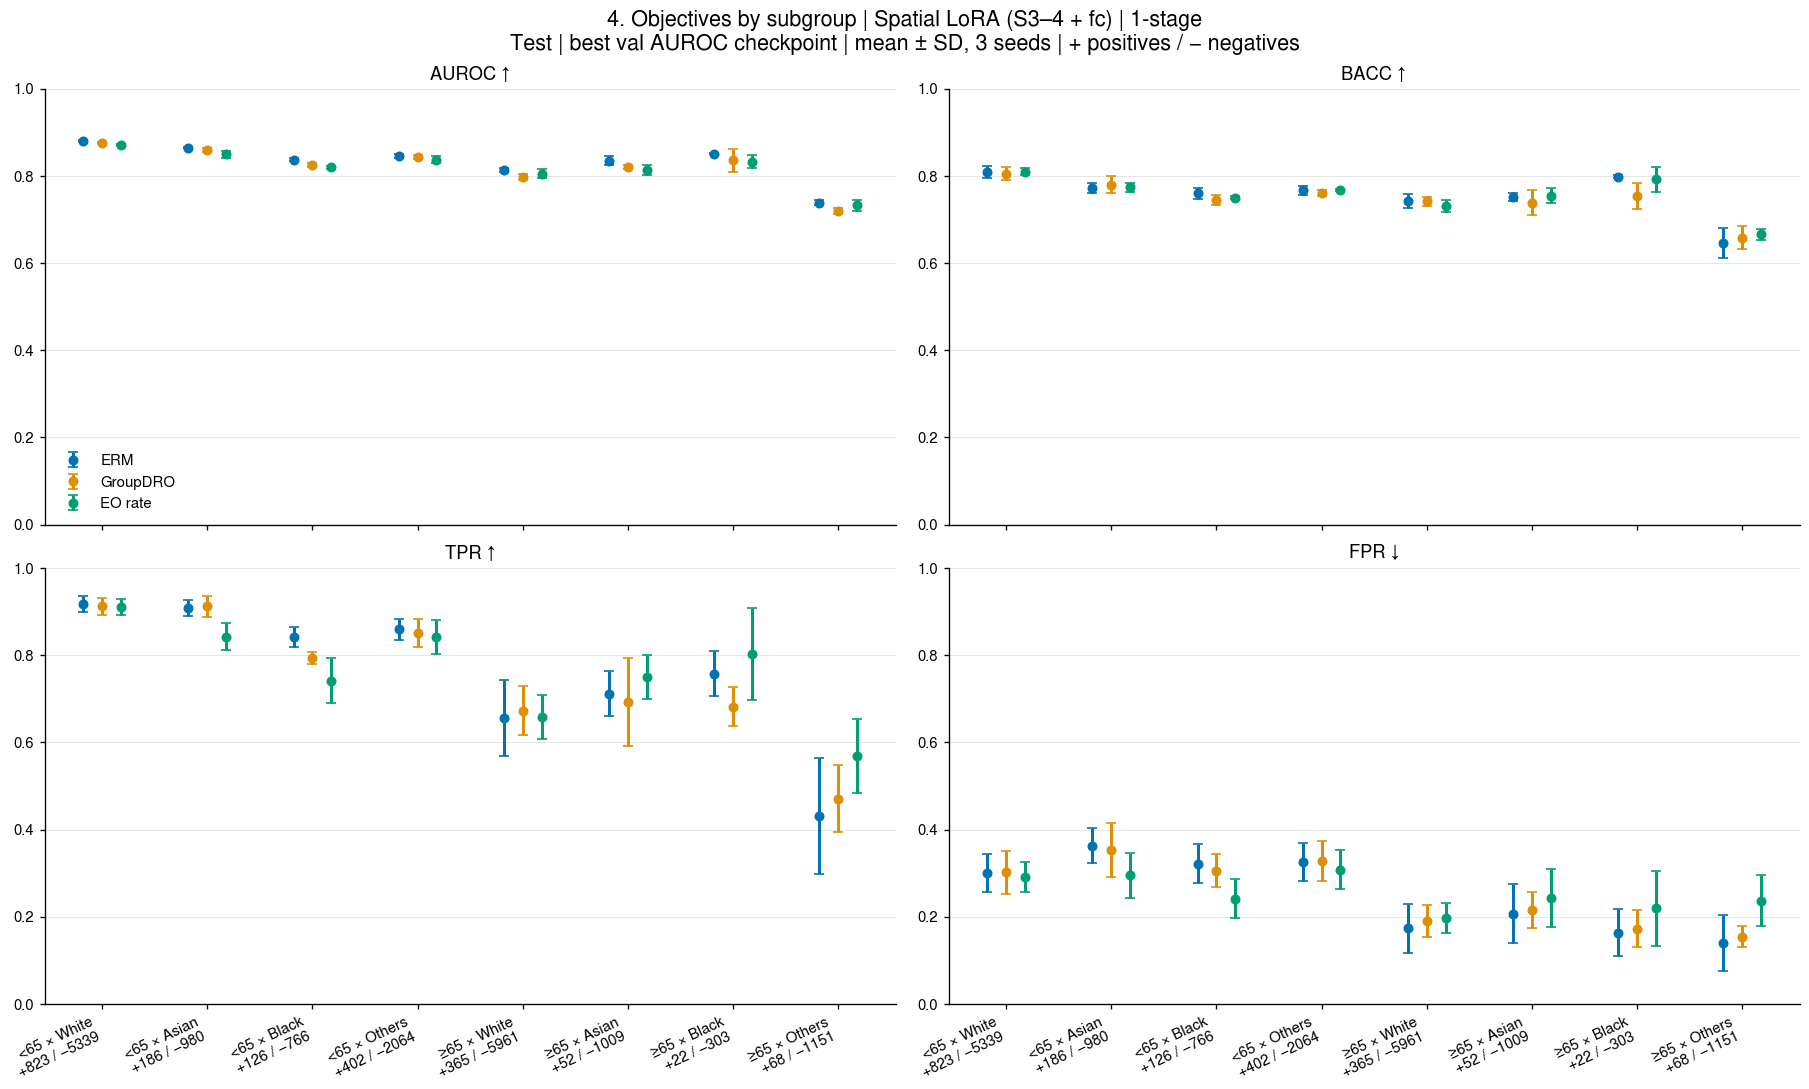

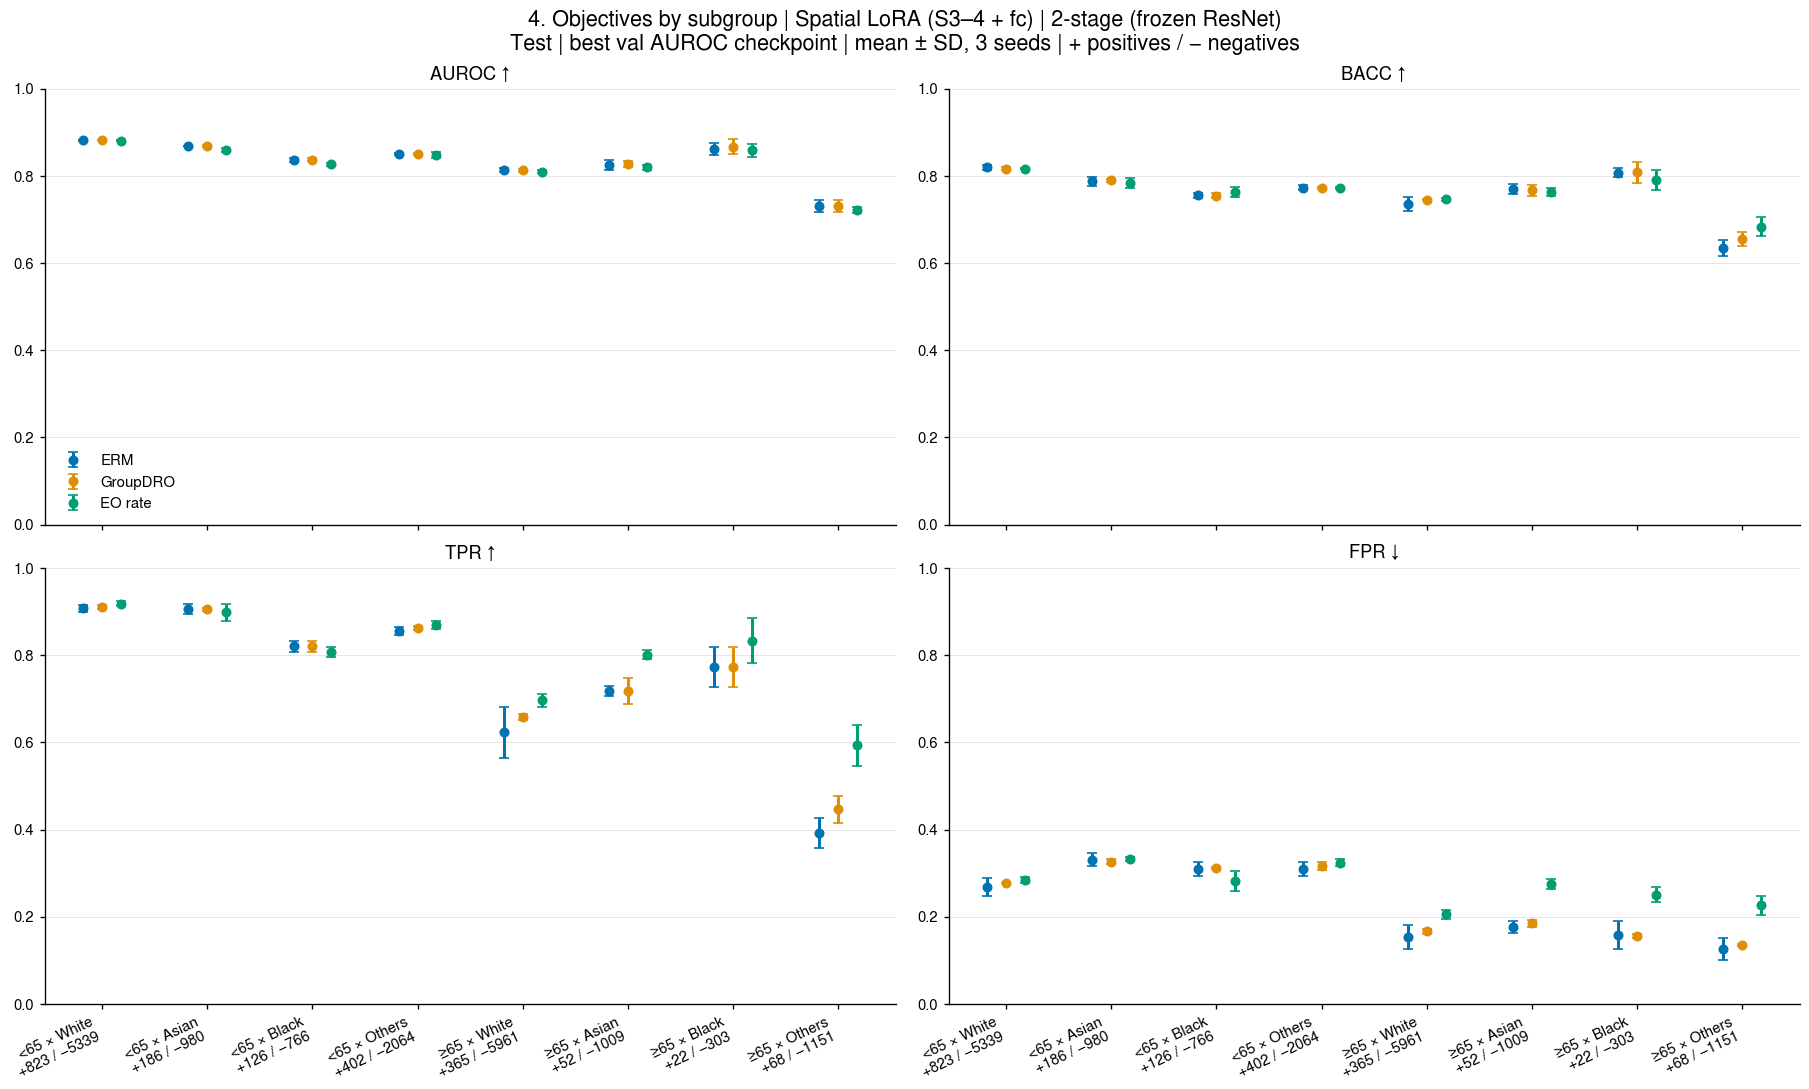

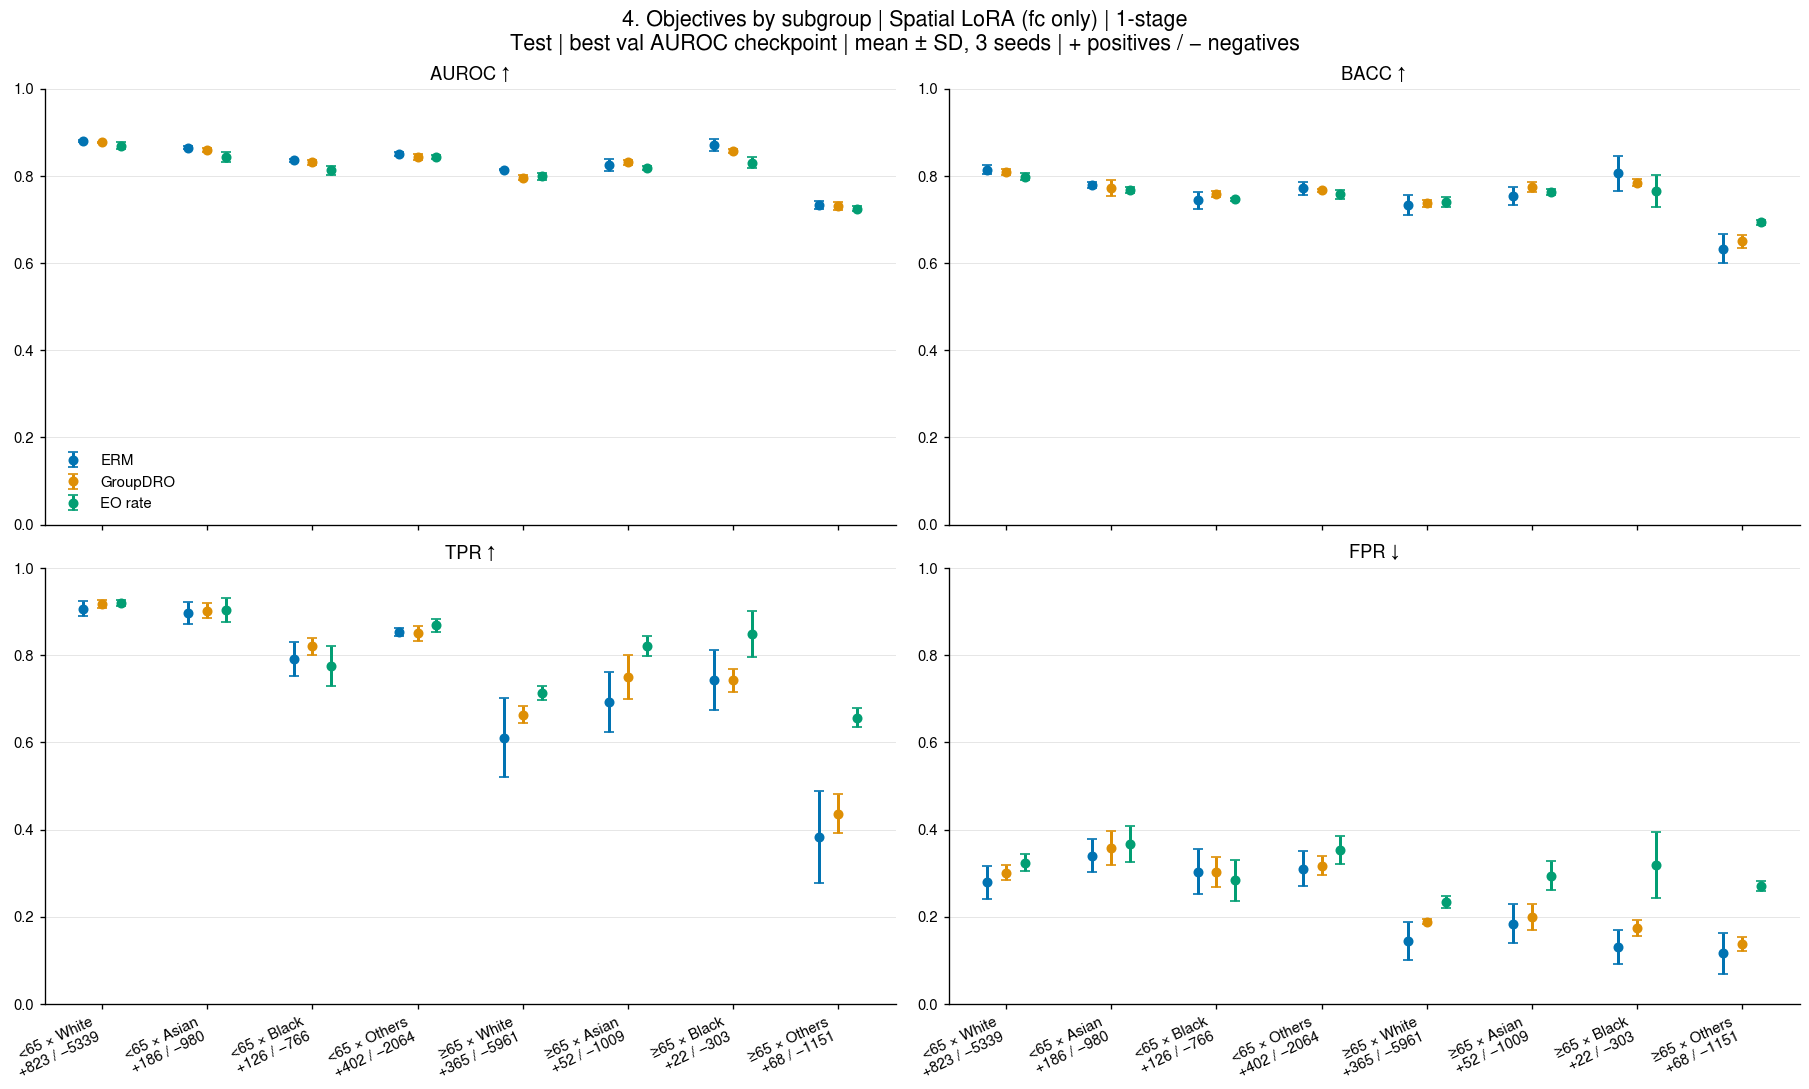

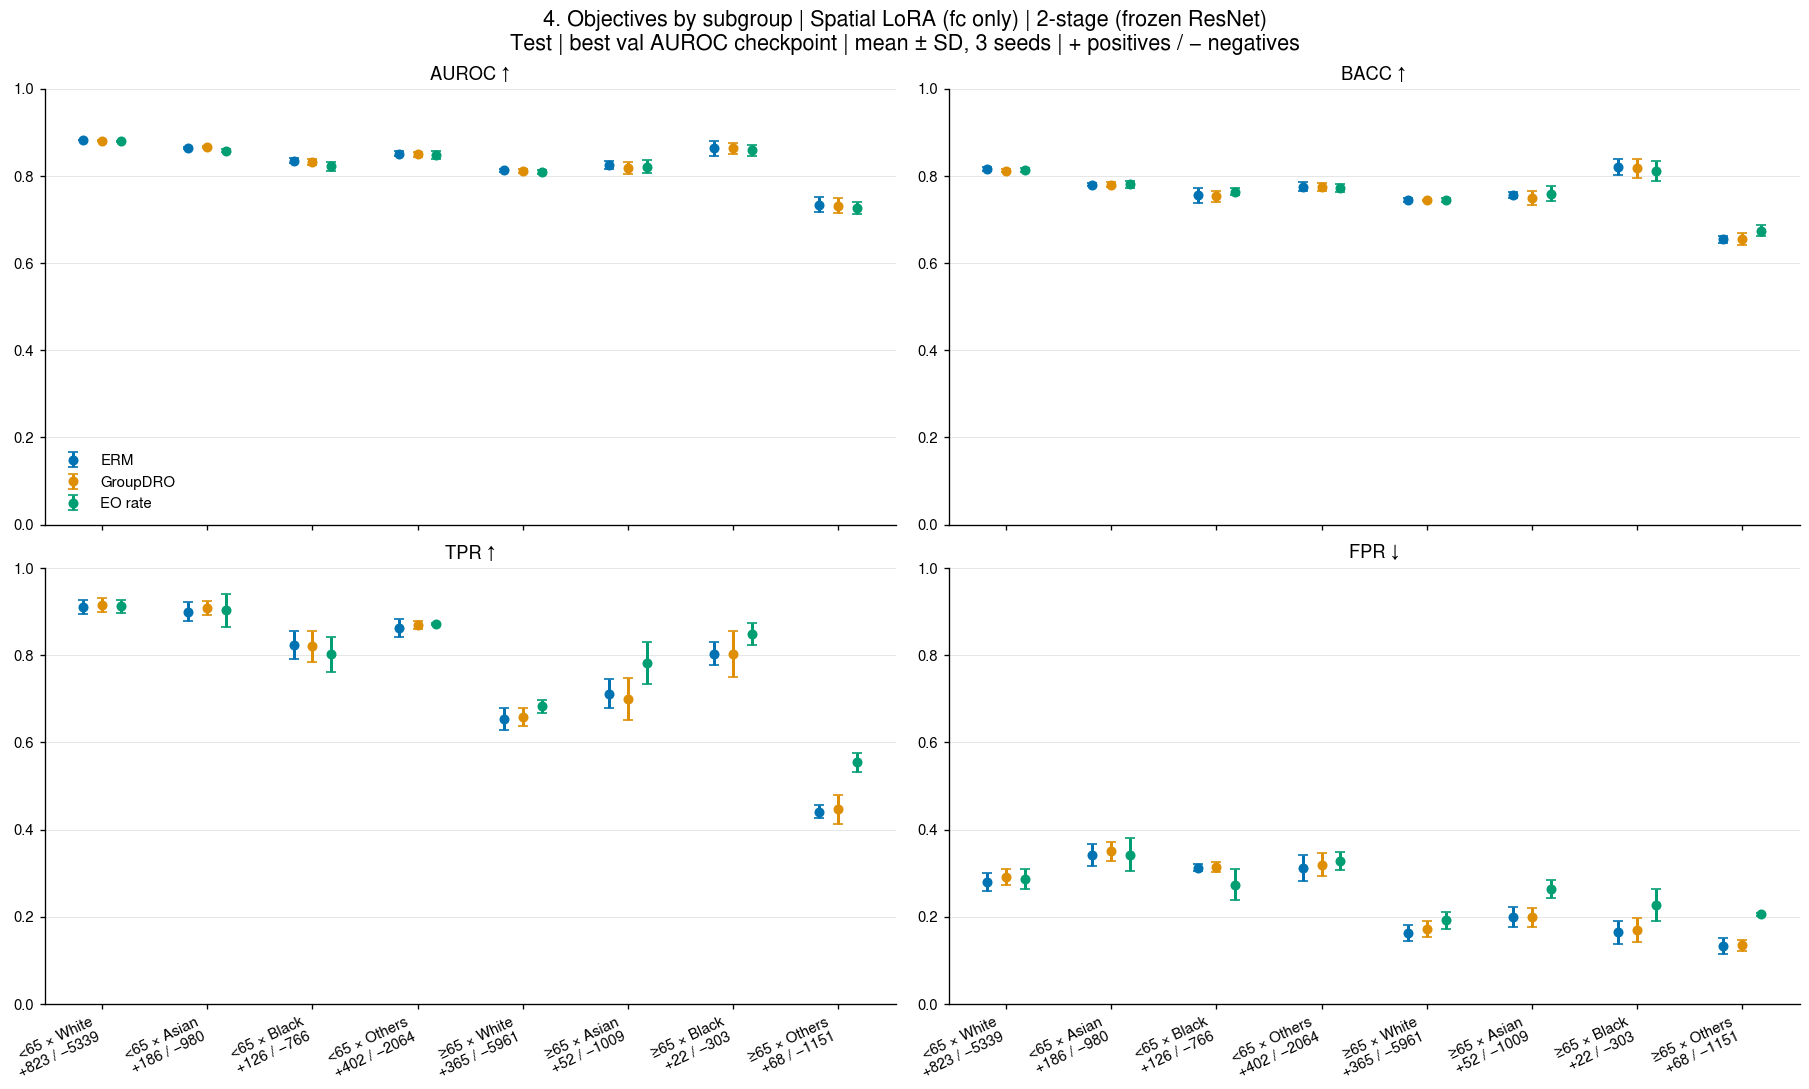

In [7]:
for model in ("spatial_lora", "spatial_lora_fc"):
    for procedure in STAGE:
        selected = groups.loc[(groups.model == model) & (groups.procedure == procedure)]
        group_panels(
            selected,
            "objective",
            OBJECTIVES,
            OBJECTIVE,
            "4. Objectives by subgroup | " + MODEL[model] + " | " + STAGE[procedure],
            f"04_objective_groups_{model}_{procedure}",
        )

観察：S3–4＋fc・1-stageのEO-rateでは、65歳未満×AsianのFPRが0.3633→0.2949と下がる一方、65歳以上×Othersは0.1396→0.2369と上がる。gap縮小には両端の動きが含まれる。

## 5. 1 runのGroupDRO重み推移

Spatial LoRA (stage3–4 + fc)、1-stage、seed 42を事前指定する。
左はepoch内の平均q、右はepoch末のq。qは確率分布なので各時点で8群の和が1。
縦破線はbest val AUROCのepochで、test結果を見て選んだ時点ではない。

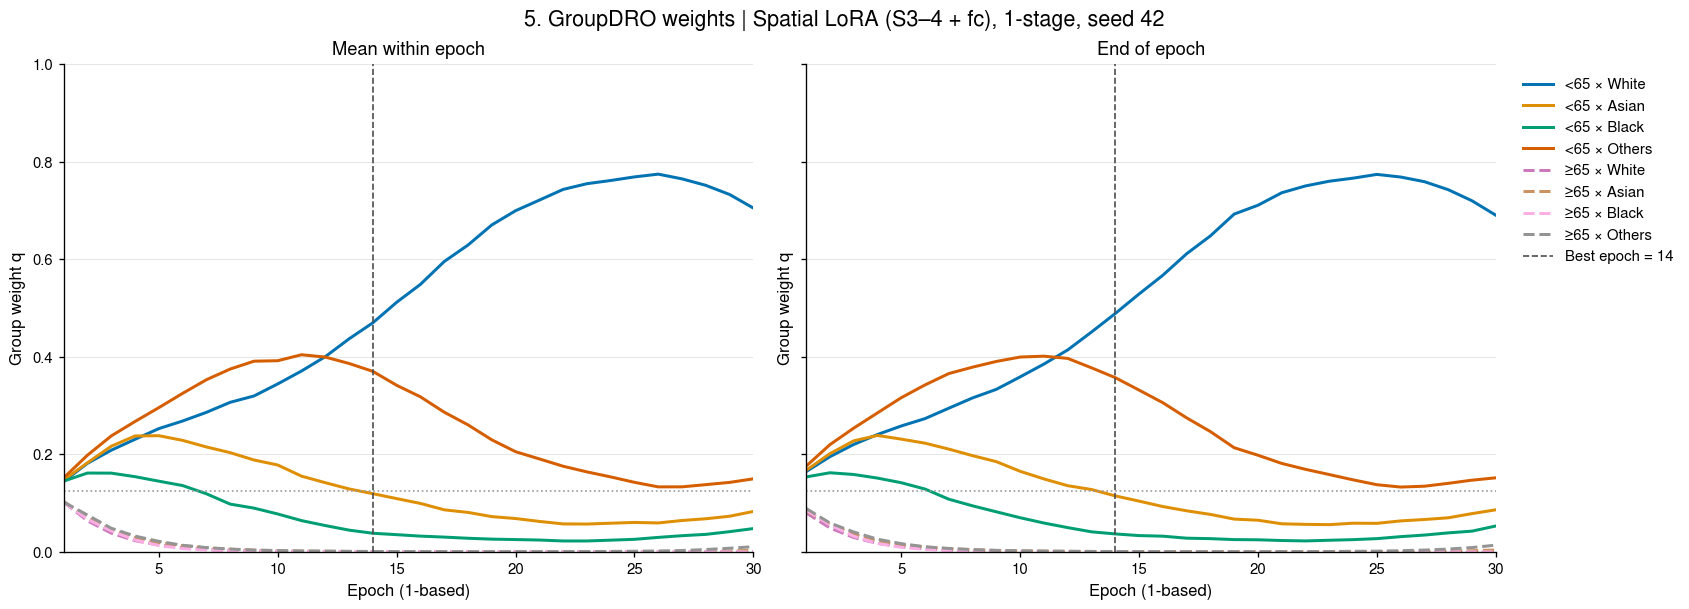

In [8]:
chosen = table.query(
    "model == 'spatial_lora' and procedure == 'one_stage' and objective == 'group_dro' and seed == 42"
).iloc[0]
chosen_q = q_history.loc[q_history.run_id == chosen.run_id]
best_epoch = selections.loc[selections.run_id == chosen.run_id, "best_epoch"].item()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, kind, label in zip(axes, ("q_mean", "q_end"), ("Mean within epoch", "End of epoch"), strict=True):
    for g, group_label in enumerate(GROUP_LABELS):
        line = chosen_q.loc[(chosen_q.kind == kind) & (chosen_q.group == g)]
        ax.plot(line.epoch, line.q, label=group_label, linestyle="-" if g < 4 else "--")
    ax.axhline(1 / 8, color="0.6", linestyle=":", linewidth=1)
    ax.axvline(best_epoch, color="0.3", linestyle="--", linewidth=1, label=f"Best epoch = {best_epoch}")
    ax.set(xlabel="Epoch (1-based)", ylabel="Group weight q", title=label, ylim=(0, 1), xlim=(1, 30))
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
fig.suptitle("5. GroupDRO weights | Spatial LoRA (S3–4 + fc), 1-stage, seed 42", fontsize=13)
save_figure(fig, "05_group_dro_weights")
chosen_q.to_csv(RESULTS / "selected_q_history.csv", index=False)

観察：指定runのbest epoch 14で、q_endは65歳未満×Whiteに0.4891、同Othersに0.3574。qは学習損失の重みであり、FPRやAUROCの最悪群と同義ではない。

## 6. validationの学習推移

ERM / GroupDRO / EO rateを同一モデル・同一stageで比較する。
横軸は1始まりのepoch（2-stageでは補正学習開始からのepoch）。線はseed平均、帯は±SD。
上段が公平性、下段がglobal指標。global TPR/FPRはログから復元し、TP/FP件数の整数性を検算する。
学習時bf16-mixedとcache float32の差は別表へ保存する。

**worst-FPRの全epoch値は未記録**。ERM/GroupDROは途中のcheckpointも残っていないため、
その枠には各seedのbest checkpointで直接計算した点だけを表示し、点を線で結ばない。
この点は他の曲線のようなseed平均ではない。

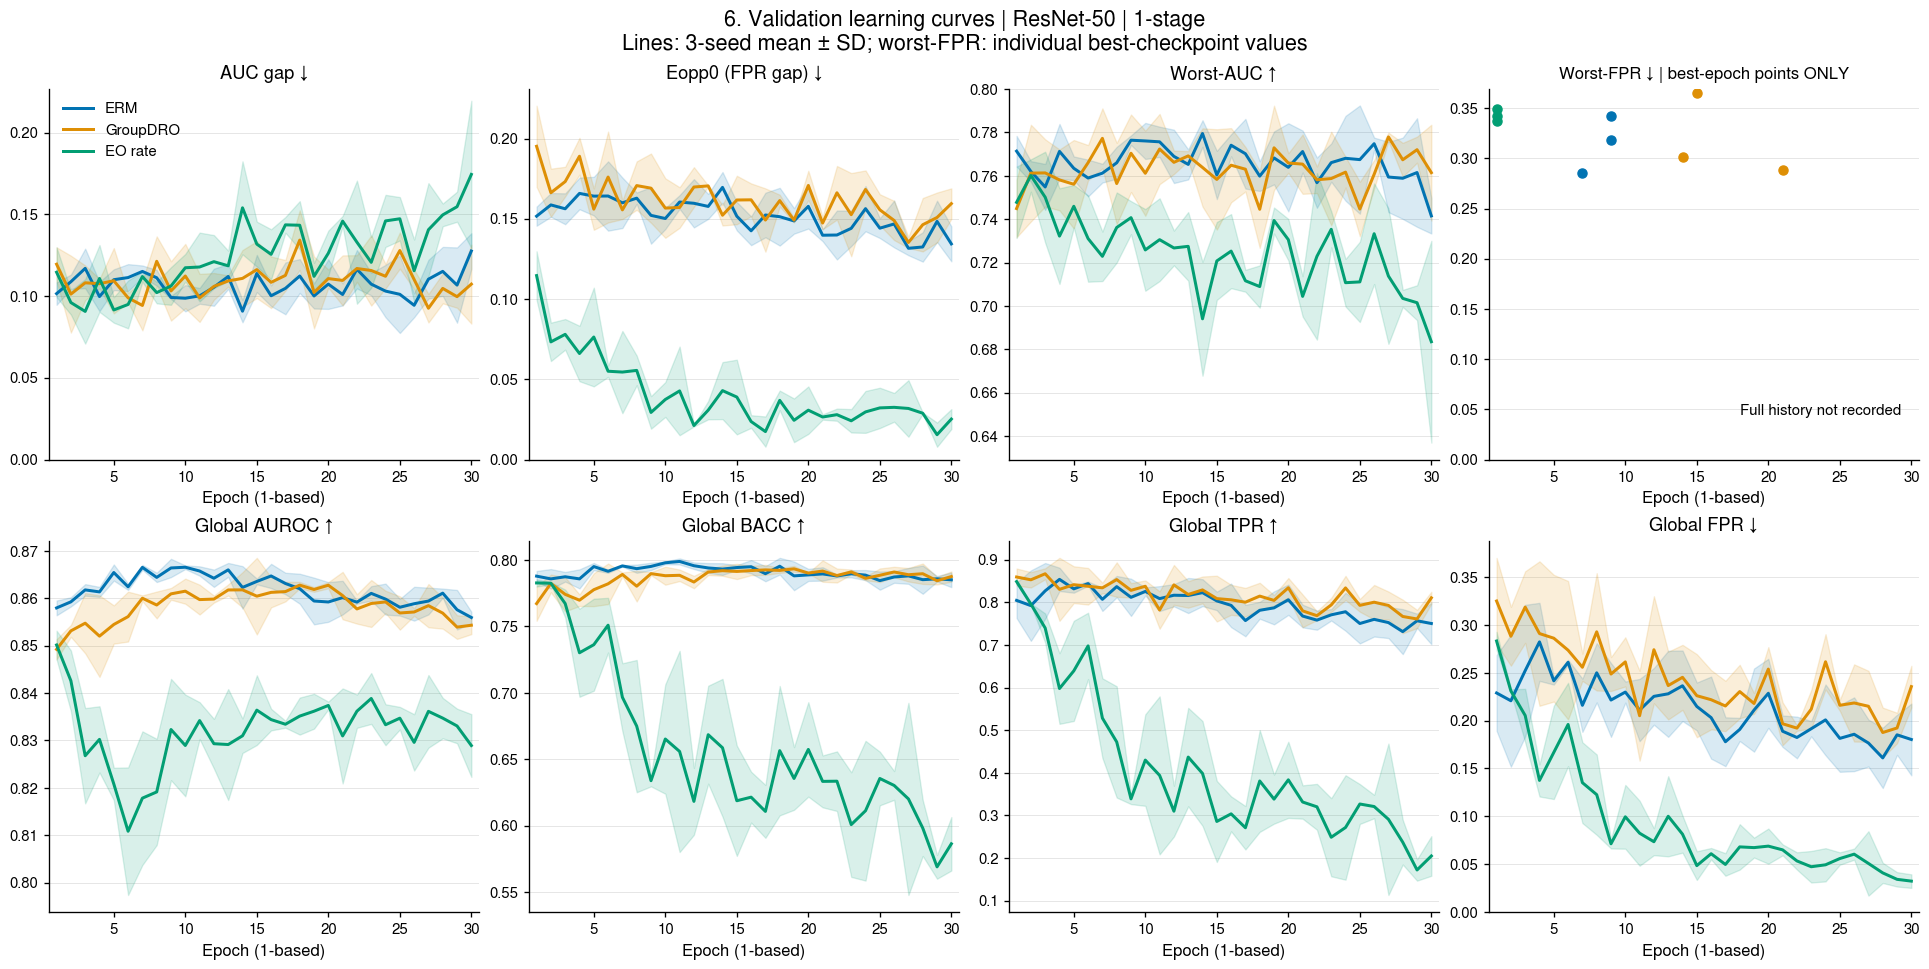

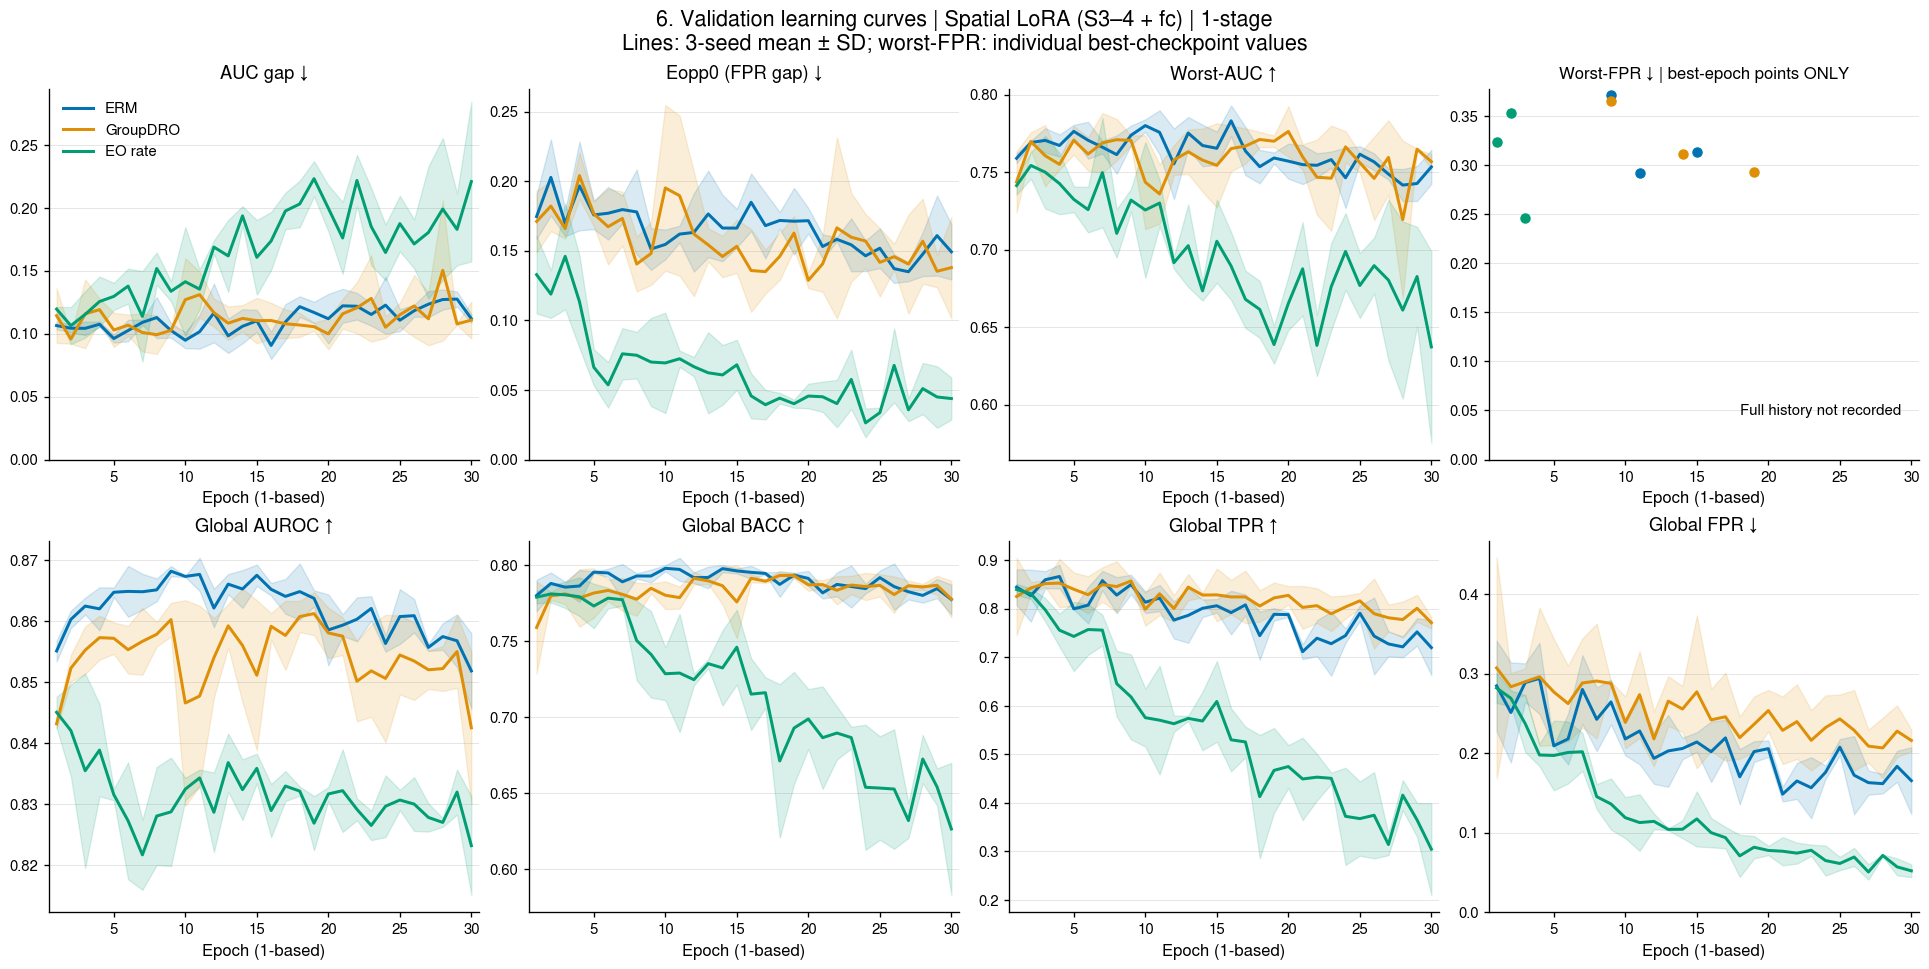

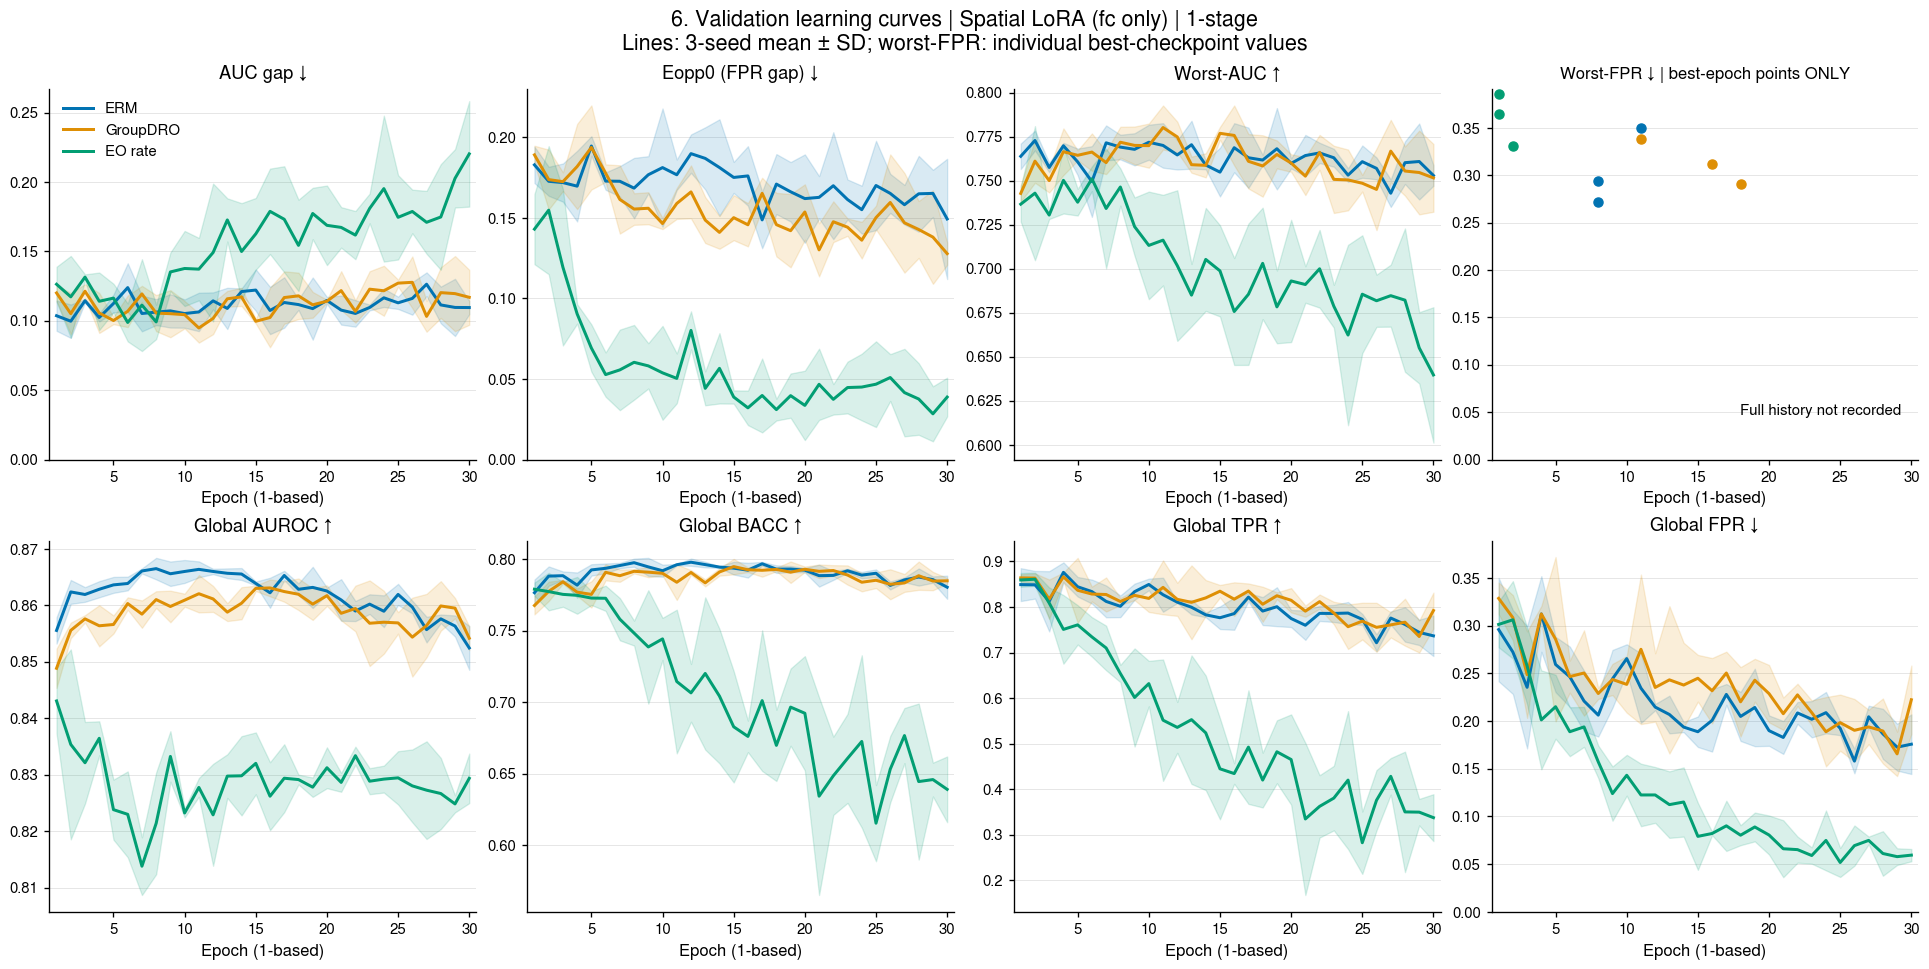

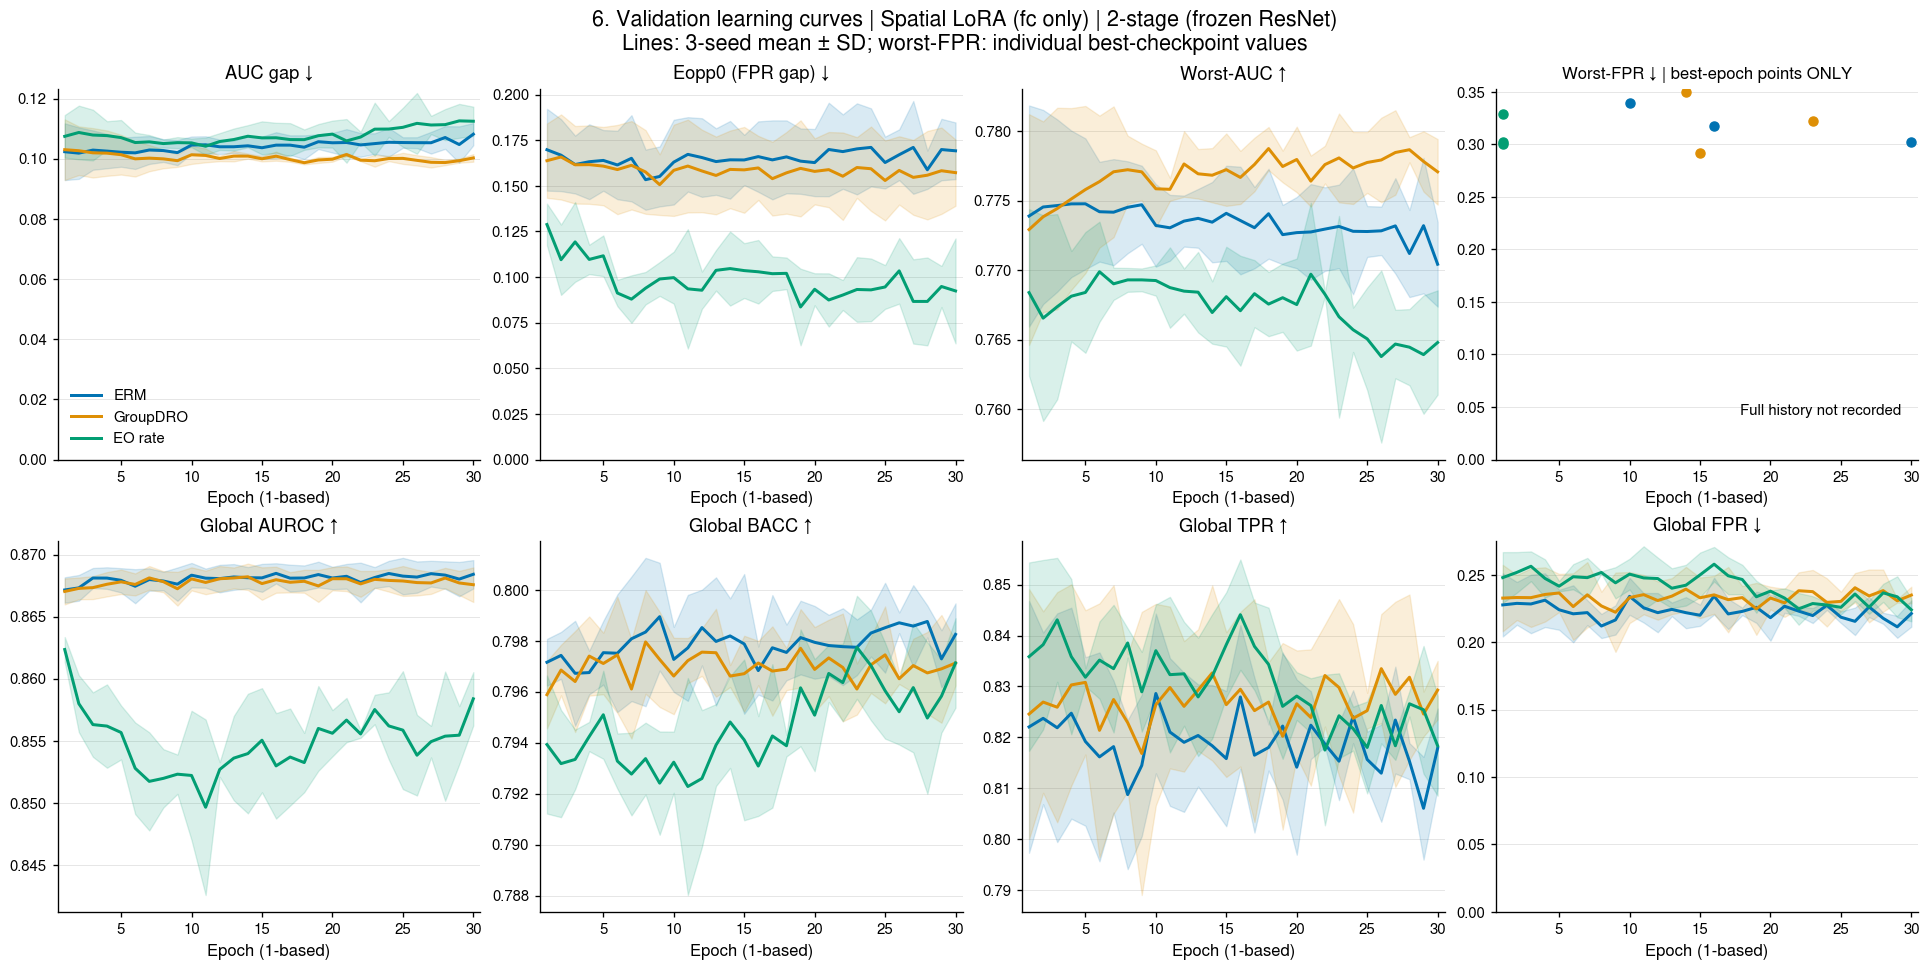

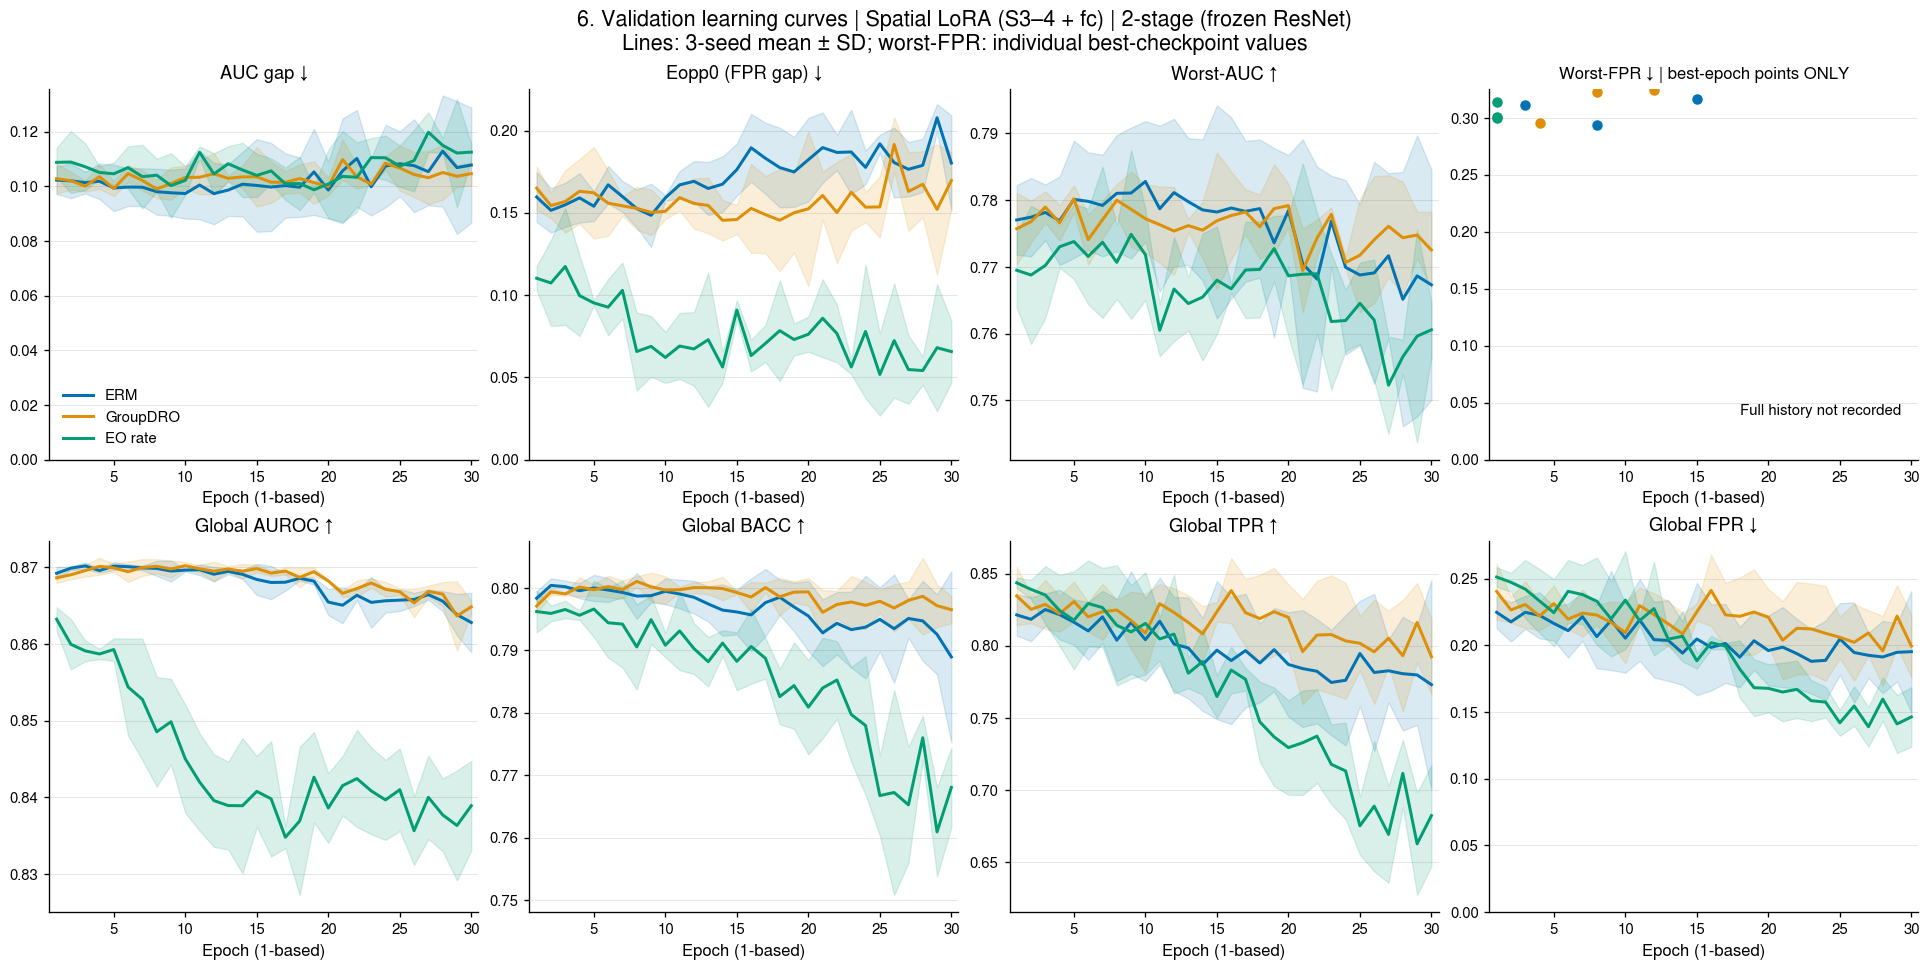

In [9]:
for procedure, model in table[["procedure", "model"]].drop_duplicates().itertuples(index=False, name=None):
    selected = history_means.loc[(history_means.procedure == procedure) & (history_means.model == model)]
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, metric in zip(axes.flat, FAIRNESS + GROUP_METRICS, strict=True):
        ax.set_title(("Global " if metric in GROUP_METRICS else "") + TITLES[metric])
        for objective in OBJECTIVES:
            line = selected.loc[selected.objective == objective].sort_values("epoch")
            color = COLORS[objective]
            if metric == "worst_fpr":
                dots = validation.loc[
                    (validation.procedure == procedure)
                    & (validation.model == model)
                    & (validation.objective == objective)
                ]
                dots = dots.merge(selections[["run_id", "best_epoch"]], on="run_id")
                ax.scatter(dots.best_epoch, dots.worst_fpr, color=color, s=30, label=OBJECTIVE[objective])
            else:
                x, y, sd = (line[c].to_numpy() for c in ("epoch", metric, metric + "_sd"))
                ax.plot(x, y, color=color, label=OBJECTIVE[objective])
                ax.fill_between(x, np.maximum(0, y - sd), np.minimum(1, y + sd), color=color, alpha=0.15)
        ax.set(xlabel="Epoch (1-based)", xlim=(0.5, 30.5))
        if metric in ("auroc_gap", "eopp0", "worst_fpr", "fpr"):
            ax.set_ylim(bottom=0)
        if metric == "worst_fpr":
            ax.set_title("Worst-FPR ↓ | best-epoch points ONLY", fontsize=10)
            ax.text(0.96, 0.12, "Full history not recorded", transform=ax.transAxes, ha="right", fontsize=9)
    axes[0, 0].legend(fontsize=9)
    fig.suptitle(
        "6. Validation learning curves | "
        + MODEL[model]
        + " | "
        + STAGE[procedure]
        + "\nLines: 3-seed mean ± SD; worst-FPR: individual best-checkpoint values",
        fontsize=13,
    )
    save_figure(fig, f"06_learning_{model}_{procedure}")

観察：EO-rateのbestは全runでepoch 1〜3。S3–4＋fc・1-stageのepoch 1→30では、Eopp0が0.1328→0.0438に下がる一方、TPRは0.8396→0.3047、BACCは0.7787→0.6265に下がる。Eopp0の低下だけを改善として扱えない。fcのみ・2-stageでは低下の程度が異なる。

## 対応するseedの差と観察用の表

モデル差は同seedの親ResNet ERM、損失差は同モデル・同stageのERMを基準にする。
平均±SDだけで「効果なし」「有意に改善」と断定しない。全体性能とTPR/FPRの変化も併記する。

In [10]:
metrics = FAIRNESS + GROUP_METRICS
paired = []
parent = test.query("model == 'resnet' and objective == 'erm'").set_index("seed")
for procedure, model, objective in test[KEYS].drop_duplicates().itertuples(index=False, name=None):
    selected = test.loc[
        (test.procedure == procedure) & (test.model == model) & (test.objective == objective)
    ].set_index("seed")
    if objective == "erm":
        reference = parent
        baseline = "parent ResNet ERM"
    else:
        reference = test.loc[
            (test.procedure == procedure) & (test.model == model) & (test.objective == "erm")
        ].set_index("seed")
        baseline = "same-model same-stage ERM"
    delta = selected[metrics] - reference[metrics]
    for seed, row in delta.iterrows():
        paired.append(
            {
                "procedure": procedure,
                "model": model,
                "objective": objective,
                "baseline": baseline,
                "seed": seed,
                **row.to_dict(),
            }
        )
paired = pd.DataFrame(paired)
paired.to_csv(RESULTS / "paired_deltas_by_seed.csv", index=False)
delta_means = aggregate(paired, KEYS + ["baseline"], metrics)
delta_means.to_csv(RESULTS / "paired_deltas_mean_sd.csv", index=False)
display(delta_means[KEYS + ["baseline"] + metrics].round(4))
BOOK.close()
images = []
for path in sorted(FIGURES.glob("*.png")):
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    images.append(
        f'<section id="{path.stem}"><h2>{path.stem}</h2>'
        f'<img src="data:image/png;base64,{encoded}" alt="{path.stem}"></section>'
    )
html = """<!doctype html><html lang="ja"><meta charset="utf-8"><title>CheXpert 公平性の比較</title>
<style>body{max-width:1500px;margin:32px auto;padding:0 24px;font-family:system-ui;background:#fafafa;color:#18212b}
img{width:100%;height:auto}
section{background:white;padding:20px;margin:32px 0;border:1px solid #ddd}
h2{font-size:18px}p{line-height:1.8}</style>
<h1>属性条件付き予測と公平性</h1>
<p>CheXpert race-known・8群・3 seed。図1–4はbest validation AUROC checkpointのtest評価、図6はvalidationの学習推移。
エラーバーと帯はseed間SD。No Findingが陽性、worst-FPRは8群の最大FPR。<br>
図6のworst-FPRはbest epochの点のみ（全epochの値は未記録）。
EO rateは訓練データ量と抽出方法も異なる。
図2・4の群名には陽性・陰性件数を併記。</p>"""
(FIGURES / "index.html").write_text(html + "".join(images) + "</html>", encoding="utf-8")
print("Saved PNG/PDF figures:", len(images))

,procedure,model,objective,baseline,auroc_gap,eopp0,worst_group_auroc,worst_fpr,auroc,bacc,tpr,fpr
0,one_stage,resnet,erm,parent ResNet ERM,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,one_stage,spatial_lora,erm,parent ResNet ERM,-0.0086,0.0140,0.0088,0.0262,0.0009,-0.0025,0.0109,0.0160
2,one_stage,resnet,eo_rate,same-model same-stage ERM,-0.0087,-0.0365,-0.0080,0.0527,-0.0145,-0.0173,0.0295,0.0641
3,one_stage,resnet,group_dro,same-model same-stage ERM,-0.0061,-0.0025,0.0013,0.0126,-0.0047,-0.0057,-0.0060,0.0053
4,one_stage,spatial_lora,eo_rate,same-model same-stage ERM,-0.0035,-0.0986,-0.0064,-0.0505,-0.0160,-0.0086,-0.0121,0.0051
5,one_stage,spatial_lora,group_dro,same-model same-stage ERM,0.0150,-0.0247,-0.0191,-0.0102,-0.0081,-0.0052,-0.0036,0.0068
6,one_stage,spatial_lora_fc,eo_rate,same-model same-stage ERM,-0.0046,-0.0867,-0.0084,0.0333,-0.0175,-0.0148,0.0398,0.0695
7,one_stage,spatial_lora_fc,group_dro,same-model same-stage ERM,-0.0032,-0.0057,-0.0019,0.0184,-0.0075,-0.0040,0.0186,0.0267
8,two_stage,spatial_lora_fc,eo_rate,same-model same-stage ERM,0.0059,-0.0553,-0.0082,0.0031,-0.0061,-0.0046,0.0126,0.0218
9,two_stage,spatial_lora_fc,group_dro,same-model same-stage ERM,0.0017,0.0057,-0.0025,0.0078,-0.0015,-0.0018,0.0047,0.0083


Saved PNG/PDF figures: 15
